## <font color=#0099CC>mIAx - Taller Renta Fija - ANÁLISIS CARTERA DE RENTA FIJA</font>

En esta práctica, desarrollaremos un análisis exahustivo de un universo de Renta Fija, en concreto, de bonos corporativos. Además, construiremos y analizaremos varias carteras. 

Para ello, contaremos con la siguiente información almacenada en la carpeta *data*:
- **Universo de bonos**, con sus características esenciales (fichero *universo.csv*)
- **Histórico de precios** de cierre del universo de bonos anterior (fichero *precios_historicos_universo.csv*)
- **Curva de tipos de interés €STR** (fichero *curvaESTR.csv*)
- **Histórico de precios de otros índices** que nos serán de utilidad (fichero *precios_historicos_varios.csv*):
    - Índices de crédito: ITRAXX Main y ITRAXX XOVER. Serán útiles para la cobertura del riesgo de crédito.
    - Futuros sobre el *Schatz* (DU1), *BOBL* (OE1) y *BUND* (RX1). Serán útiles para la cobertura de los tipos de interés.
    - Índice de crédito *RECMTREU*, que valdría como benchmark de las carteras que construyamos.

No necesariamente se usará toda toda la información.

📣 <font color=#CC6600>**¡NORMAS!**</font>

La práctica se puede hacer en grupos de hasta **3 personas** y deberá entregarse antes del **26 de noviembre**. 

**ENTREGABLES**: 
* **Carpeta .zip** con el nombre del capitán del grupo.
* La carpeta debe mantener la estructura original.
* Los ficheros **funciones_aux.py** y **analisis_cartera.ipynb** deben completarse según se considere. 
* Deberán ser ejecutables y **enviarse ya debidamente ejecutados** y con los **resultados guardados**.
* Todo el **código debe estar comentado y razonado.**
* Las **celdas de texto deben responder explícitamente a las preguntas realizadas.**
* En la subcarpeta **"results" deberán estar los ficheros .csv** que se piden en los diferentes apartados.

Cada grupo expondrá una parte de los ejercicios en la clase del día 26, donde la resolveremos juntos a modo de taller. Esta exposición contará hasta **1 punto** de la nota final.
Cada apartado de esta práctica también contará hasta **1 punto** de la nota final.

Además, se valorará positivamente para la práctica la participación en las clases.

📣 <font color=#CC6600>**¡IMPORTANTE!**</font>

Todo el código implementado debe estar debidamente comentado e incluir conclusiones de los resultados obtenidos para optar a la máxima puntuación. Asimismo, se debe responder a las preguntas planteadas.

Las propuestas de mejora o posibles trabajos futuros se valorarán positivamente también.

Usa las fuentes de información que consideres necesarias para apoyar tus respuestas.

### <font color=#336699>Librerías</font>

In [101]:
import importlib
import os
import sys
from decimal import Decimal
from math import exp, sqrt
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Localizamos los módulos del taller desde src/ o desde la raíz del proyecto.
carpeta_src = "." if os.path.isfile("funciones_aux.py") else "src"
if carpeta_src not in sys.path:
    sys.path.insert(0, carpeta_src)

import backtest
import funciones_aux
import mandato

# Al volver a ejecutar esta celda se cargan los cambios locales sin reiniciar el kernel.
importlib.reload(backtest)
importlib.reload(funciones_aux)
importlib.reload(mandato)

from funciones_aux import valoracion_bono
from mandato import RATINGS_IG, RATINGS_HY, candidatos_mandato, optimizar_mandato

In [102]:
# Estilo
plt.style.use('dark_background')

In [103]:
# Fecha de análisis
fecha_analisis = pd.to_datetime('2026-10-01')

### <font color=#336699>1. Datos</font>

**Análisis de datos.** En esta sección, haremos un análisis de la información que tenemos de cada bono y lo que significa. Asimismo, haremos los tratamientos y limpieza que necesitemos para luego poder usarlos.

Haz un primer análisis visual de la información que tenemos del universo de bono.
Entre otras, plantéate cuestiones como:
- ¿Divisas?
- ¿Tipo de bonos? ¿Fijo/Flotante? ¿Prelación? ¿Opcionalidad? ¿Hay bonos perpetuos?
- ¿Sectores? ¿Emisores? Si invirtéramos en todos los bonos, ¿dirías a priori que la cartera está diversificada?
- ¿Ratings? (Riesgo de crédito)
- ¿Otros datos cuantitativos?
    - Riesgo de liquidez - Horquillas y nominal vivo
- ¿Hay *gaps* en la información que vamos a tener que tratar?

**Guarda en "results" dos ficheros .csv:
1. "control_calidad_universo.csv" generado con la infomación del fichero universo.csv y que contenga las siguientes columnas para cada característica de los bonos:**
- número de observaciones
- número de datos *missing*
- número de valores únicos
- mínimo y máximo si aplica

2. "control_calidad_precios.csv" generado con la infomación del fichero precios_historicos_universo.csv y que para cada bono contenga las siguientes columnas:
- número de observaciones
- número de datos *missing*
- mínimo y máximo
- fecha inicio y fecha fin de cotización

Saca conclusiones de estas tablas de control. Identifica al menos 2 posibles problemas de calidad en estos dos ficheros que puedan afectar a los cálculos posteriores. Para cada uno, indica:
- problema
- tratamiento propuesto
- número de bonos afectados
- consecuencia de no tratarlo

In [104]:
# Ejecutamos desde src/ (carpeta del notebook) o desde la raíz del proyecto.
carpeta_datos = "../data/" if os.path.isdir("../data") else "data/"

# Cada ejercicio guarda sus CSV en su propia carpeta.
carpeta_results = Path(carpeta_datos).resolve().parent / "results"


def carpeta_apartado(numero):
    carpeta = carpeta_results / f"apartado-{numero}"
    carpeta.mkdir(parents=True, exist_ok=True)
    return carpeta


universo = pd.read_csv(carpeta_datos + "universo.csv", sep=";")

#### Control de calidad del universo

In [105]:
# Revisamos las columnas originales antes de añadir variables derivadas.
columnas_numericas = universo.select_dtypes(include="number").drop(
    columns=["PD 1YR", "Coupon Frequency"]
)
control_calidad_universo = pd.DataFrame({
    "Observaciones": universo.count(),
    "Datos missing": universo.isna().sum(),
    "Valores únicos": universo.nunique(),
    "Mínimo": columnas_numericas.min(),
    "Máximo": columnas_numericas.max(),
})
# Formateamos solo los límites y conservamos el valor de las cifras pequeñas.
for limite in ("Mínimo", "Máximo"):
    control_calidad_universo[limite] = control_calidad_universo[limite].map(
        lambda valor: "No aplica" if pd.isna(valor) else f"{Decimal(str(valor)).normalize():f}"
    )

control_calidad_universo.to_csv(
    carpeta_apartado(1) / "control_calidad_universo.csv",
    index_label="Característica",
    lineterminator="\n",
)
display(control_calidad_universo)

,Observaciones,Datos missing,Valores únicos,Mínimo,Máximo
Ask Price,2165,0,2163,43.34221,121.6583
Bid Price,2165,0,2162,42.8634,121.1417
Callable,2165,0,2,No aplica,No aplica
Ccy,2165,0,1,No aplica,No aplica
Coupon,2165,0,314,0,9.875
Coupon Frequency,2165,0,2,No aplica,No aplica
Coupon Type,2165,0,2,No aplica,No aplica
Description,2165,0,2163,No aplica,No aplica
First Coupon Date,2165,0,1142,No aplica,No aplica
ISIN,2165,0,2165,No aplica,No aplica


De las **2.165 emisiones**, las 583 que carecen de `Next Call Date` tienen `Callable = N`. Los 18 bonos sin vencimiento ni penúltimo cupón son perpetuos, rescatables y de cupón variable. Los 11 bonos con una fecha de call anterior al análisis siguieron teniendo cotizaciones posteriores. Su tratamiento como rescatados en la valoración responde a la hipótesis del apartado 2. [Universo.csv](../data/universo.csv)

Faltan **23 valores de `PD 1YR`**, la probabilidad de impago a un año, en 13 emisores. Hay **372 bonos `NR` y 3 ratings vacíos**. Todos los ISIN son únicos y los precios MID están dentro de sus horquillas bid–ask. [Control de calidad del universo](../results/apartado-1/control_calidad_universo.csv)

Los **9 bonos semestrales** se valoran con su frecuencia. Los **14 de cupón cero** tienen cupón corrido cero y un único pago de nominal al vencimiento efectivo. 

#### <font color=#808080>Divisas</font>

In [106]:
print(f"Diferentes divisas: {universo['Ccy'].value_counts()}")

Diferentes divisas: Ccy
EUR    2165
Name: count, dtype: int64


Como podemos observar el universo de bonos solo tiene **una divisa**, evitando que haya problemas en la gestión de distintas divisas

#### <font color=#808080>Tipos de bono</font>

In [107]:
for campo in ["Coupon Type", "Coupon Frequency", "Seniority", "Callable"]:
    display(universo[campo].value_counts(dropna=False).rename("Emisiones"))

display(pd.Series({
    "Sin vencimiento contractual": universo["Maturity"].isna().sum(),
    "Cupón cero": universo["Coupon"].eq(0).sum(),
}))

Coupon Type
FIXED       1835
VARIABLE     330
Name: Emisiones, dtype: int64

Coupon Frequency
1    2156
2       9
Name: Emisiones, dtype: int64

Seniority
Sr Unsecured        1614
Sr Non Preferred     182
Sr Preferred         165
Subordinated         147
Jr Subordinated       24
Secured               20
1st lien              13
Name: Emisiones, dtype: int64

Callable
Y    1582
N     583
Name: Emisiones, dtype: int64

Sin vencimiento contractual    18
Cupón cero                     14
dtype: int64

Como podemos observar tenemos cupones de tipo **fijo** y **flotante**, dónde la mayoría son de tipo fijo, no encontramos bonos de tipo mixto, la frecuencia de los bonos es anual en **2156 casos** en los **9 restantes** es cada 6 meses. En cuanto al seniority encontramos que la mayoría son bonos `Sr Unsecured`. Hay 1582 bonos con opcionalidad. Finalmente hablando de los bonos con perpetuidad encontramos **18 bonos perpetuos** y **14 de cupon 0**

#### <font color=#808080>Sectores y emisores</font>

Industry Sector
Financial                 969
Consumer, Non-cyclical    391
Industrial                199
Communications            168
Consumer, Cyclical        165
Utilities                 146
Basic Materials            65
Technology                 49
Energy                     13
Name: Sectores, dtype: int64

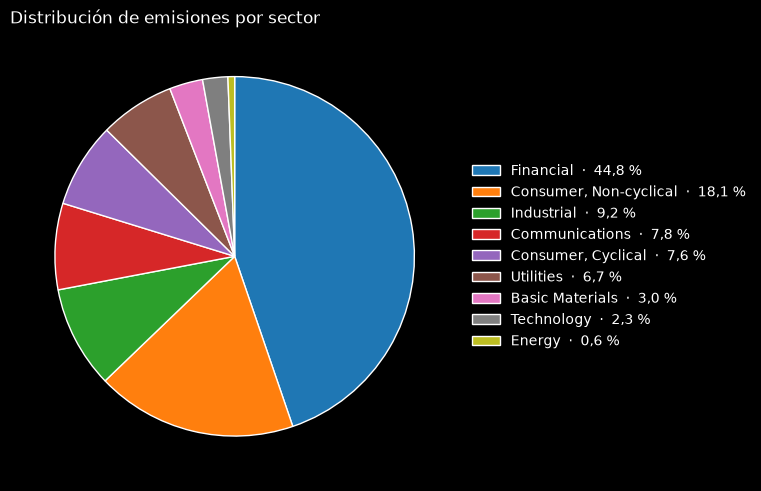

Issuer
BANQUE FED CRED MUTUEL     32
BNP PARIBAS                25
BPCE SA                    23
ORANGE SA                  22
VOLKSWAGEN INTL FIN NV     21
                           ..
BAWAG GROUP AG              1
IHG FINANCE LLC             1
VESTAS WIND SYSTEMS A/S     1
BNI FINANCE BV              1
BANCA TRANSILVANIA          1
Name: Emisores, Length: 605, dtype: int64

In [108]:
sectores = universo["Industry Sector"].value_counts(dropna=False).rename("Sectores")
display(sectores)

fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
porcentajes = 100 * sectores / sectores.sum()
etiquetas = [
    f"{sector if pd.notna(sector) else 'Sin sector'}  ·  {porcentaje:.1f} %"
    for sector, porcentaje in porcentajes.items()
]
etiquetas = [etiqueta.replace(".", ",") for etiqueta in etiquetas]
sectores_grafico, _ = ax.pie(
    sectores,
    startangle=90,
    counterclock=False,
    colors=plt.get_cmap("tab10").colors[:len(sectores)],
    wedgeprops={"edgecolor": "white", "linewidth": 1},
)
ax.set_title("Distribución de emisiones por sector", loc="left")
ax.legend(sectores_grafico, etiquetas, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

display(universo["Issuer"].value_counts(dropna=False).rename("Emisores"))

Como podemos observar los sectores más predominantes son el **financiero**, el de **consumidor(No Cíclico)** y el **Industrial**. En cuanto al emisor más grande es el `Banque FED Cred Mutuel`, seguido de cerca por `BNP Paribas`.

#### <font color=#808080>Ratings (Riesgo de crédito)</font>

In [109]:
universo["Bucket"] = universo["Rating"].map(
    dict.fromkeys(RATINGS_IG, "IG") | dict.fromkeys(RATINGS_HY, "HY"),
).fillna("Sin rating")

rating = universo["Rating"].fillna("Sin dato")
tabla_ratings = pd.crosstab(rating, universo["Bucket"])

# La mediana resume la PD de las emisiones con dato en cada grupo.
pd_por_rating = universo.groupby(rating)["PD 1YR"].agg(
    **{"PD disponibles": "count", "Mediana PD 1YR": "median"}
)
pd_por_rating["Mediana PD 1YR"] = pd_por_rating["Mediana PD 1YR"].map(
    lambda valor: "Sin dato" if pd.isna(valor) else f"{Decimal(str(valor)).normalize():f}"
)
tabla_ratings = tabla_ratings.join(pd_por_rating).rename_axis(columns=None)

# Conservamos los ratings observados y dejamos al final los que están fuera de la escala.
orden_ratings = pd.Index(RATINGS_IG.union(RATINGS_HY))
ratings_en_escala = orden_ratings.intersection(tabla_ratings.index, sort=False)
otros_ratings = tabla_ratings.index.difference(orden_ratings, sort=False)
display(tabla_ratings.reindex(ratings_en_escala.append(otros_ratings)))

,HY,IG,Sin rating,PD disponibles,Mediana PD 1YR
AA+,0,6,0,6,0.00572348867
BBB,0,300,0,300,0.000200524
BBB+,0,415,0,412,0.0000792244
BBB-,0,176,0,172,0.0010981
AA-,0,96,0,94,0.000773079
AAA,0,4,0,4,0.0000000896047
A+,0,180,0,175,0.0000137989
A,0,222,0,219,0.000194493
A-,0,363,0,363,0.0000833832
AA,0,20,0,20,0.00000502964


**BBB+** es el rating más frecuente. Hay **372 bonos `NR`**(es decir sin rating) y **3 con el campo de rating vacío**. La tabla muestra cuántos bonos tienen PD disponible y su mediana por rating, en las unidades originales del fichero. En total hay **2.142 PD disponibles de 2.165 emisiones**.

La PD mediana es mayor en BBB− que en AAA, pero la relación no es monótona en la muestra. Por ejemplo, AA+ tiene una PD mediana mayor que BBB−, con solo **seis bonos de dos emisores**. Usamos la PD como contraste dentro de cada categoría y tenemos en cuenta el tamaño de la muestra antes de interpretar esas diferencias. [Universo de bonos](../data/universo.csv). Estos detalles nos podrían indicar que hay algún bono outlier a la baja en los ratings con mejor "valoración" que hacen que la mediana empeore por encima de casos como el de BBB-

#### <font color=#808080>Riesgo de liquidez - Horquillas y nominal vivo</font>

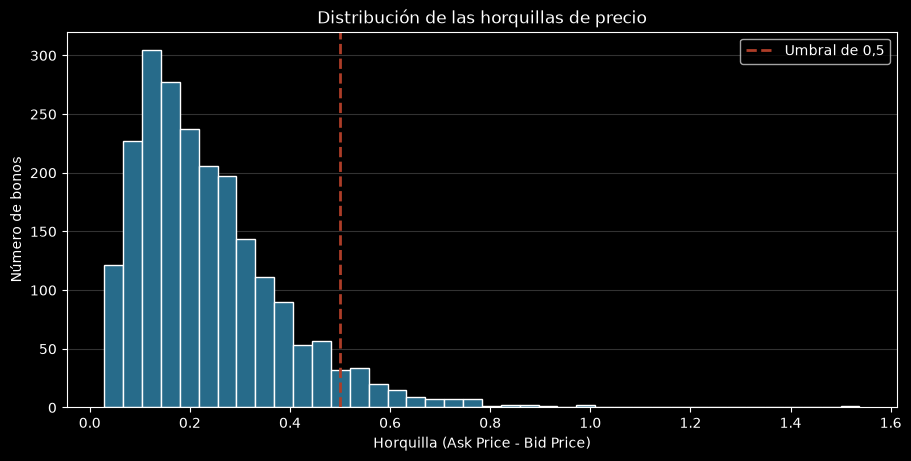

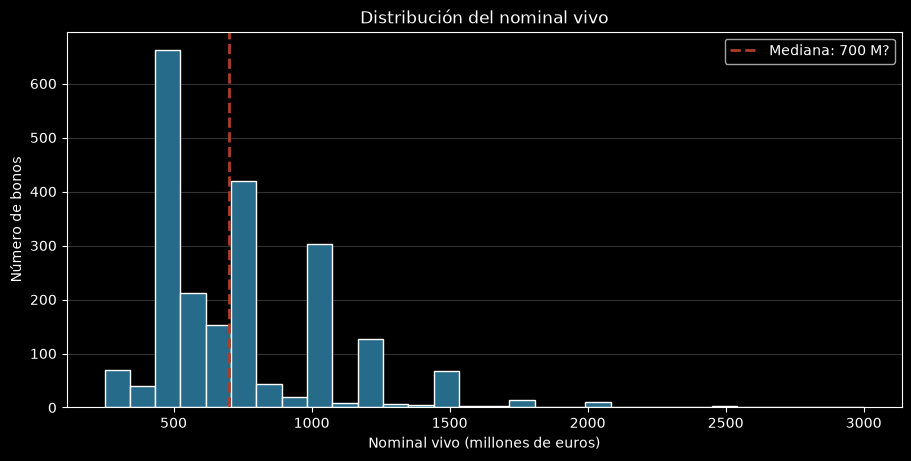

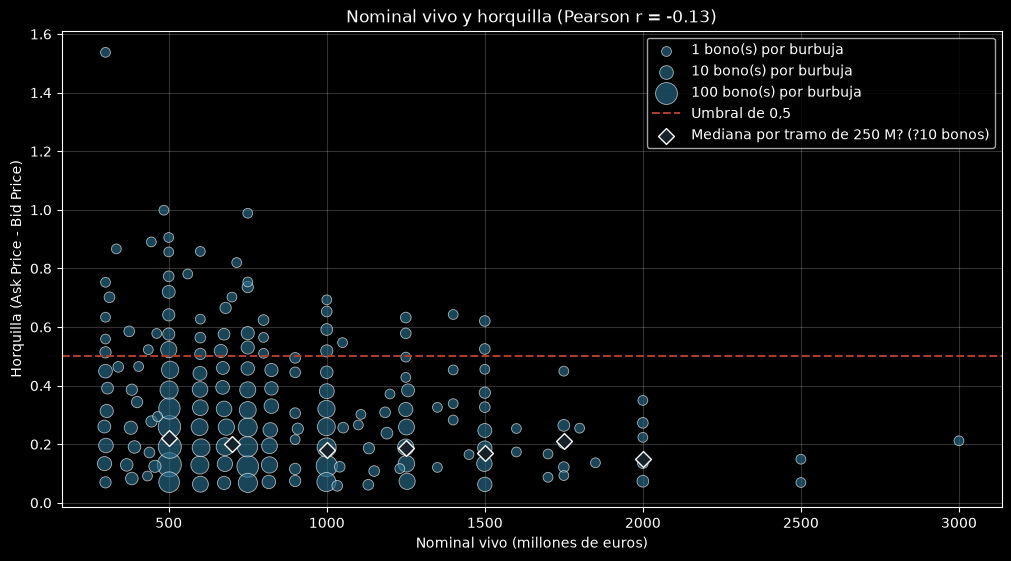

In [110]:
universo['Range'] = universo['Ask Price'] - universo['Bid Price']

# La horquilla se expresa en las mismas unidades que los precios.
horquillas = universo["Range"].dropna()
umbral = 0.5

fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
ax.hist(horquillas, bins=40, color="#276b8a", edgecolor="white")
ax.axvline(umbral, color="#ad3d28", linestyle="--", linewidth=2, label="Umbral de 0,5")
ax.set(title="Distribución de las horquillas de precio", xlabel="Horquilla (Ask Price - Bid Price)", ylabel="Número de bonos")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend()
plt.show()

nominal_vivo_millones = universo["Outstanding Amount"].dropna() / 1_000_000
mediana_nominal = nominal_vivo_millones.median()

fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
ax.hist(nominal_vivo_millones, bins=30, color="#276b8a", edgecolor="white")
ax.axvline(mediana_nominal, color="#ad3d28", linestyle="--", linewidth=2,
           label=f"Mediana: {mediana_nominal:.0f} M?")
ax.set(title="Distribución del nominal vivo",
       xlabel="Nominal vivo (millones de euros)", ylabel="Número de bonos")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend()
plt.show()

# Usamos solo los bonos con ambos datos disponibles.
datos_liquidez = universo[["Outstanding Amount", "Range"]].dropna()
nominal_millones = datos_liquidez["Outstanding Amount"] / 1_000_000
horquilla = datos_liquidez["Range"]
correlacion = nominal_millones.corr(horquilla)

umbral = 0.5
tramos = pd.cut(nominal_millones, bins=range(0, int(nominal_millones.max() // 250 + 1) * 250 + 1, 250))
medianas = (
    datos_liquidez.assign(Nominal=nominal_millones)
    .groupby(tramos, observed=True)
    .agg(Nominal=("Nominal", "median"), Horquilla=("Range", "median"),
         Bonos=("Range", "size"))
)
medianas = medianas[medianas["Bonos"] >= 10]

fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")

# Cada burbuja se sit?a en el centro de los bonos de su grupo.
grupos = (
    pd.DataFrame({"Nominal": nominal_millones, "Horquilla": horquilla})
    .groupby([pd.cut(nominal_millones, 36), pd.cut(horquilla, 23)], observed=True)
    .agg(Nominal=("Nominal", "mean"), Horquilla=("Horquilla", "mean"),
         Bonos=("Horquilla", "size"))
    .sort_values("Bonos", ascending=False)
)
tamanos = 28 + 22 * grupos["Bonos"] ** 0.5
estilo_burbujas = dict(color="#276b8a", alpha=0.65, edgecolors="white", linewidths=0.6)
burbujas = ax.scatter(grupos["Nominal"], grupos["Horquilla"], s=tamanos, **estilo_burbujas)
for cantidad in (1, 10, 100):
    ax.scatter([], [], s=28 + 22 * cantidad ** 0.5,
               label=f"{cantidad} bono(s) por burbuja", **estilo_burbujas)
ax.axhline(umbral, color="#ad3d28", linestyle="--", linewidth=1.5,
           label="Umbral de 0,5")
ax.scatter(medianas["Nominal"], medianas["Horquilla"], marker="D", s=65,
           color="#17212b", edgecolors="white", linewidths=1, zorder=4,
           label="Mediana por tramo de 250 M? (?10 bonos)")
ax.set(title=f"Nominal vivo y horquilla (Pearson r = {correlacion:.2f})",
       xlabel="Nominal vivo (millones de euros)",
       ylabel="Horquilla (Ask Price - Bid Price)")
ax.grid(alpha=0.2)
ax.set_axisbelow(True)
ax.legend(loc="upper right")
plt.show()

Asumiendo que **0.5 o 50 pb** es lo que consideraríamos como una diferencia sustancial para interpretar que un bono no es líquido podemos ver en el diagrama que la gran mayoría se encuentran dentro de la horquilla. El nominal vivo mediano es de **700 millones de euros**. El gráfico muestra que las emisiones con mayor nominal vivo tienden a presentar horquillas algo más estrechas, aunque hay bastante dispersión. Esto sugiere que un mayor nominal vivo puede favorecer la liquidez, pero por sí solo confirma poco sobre las diferencias de horquilla entre bonos.

#### <font color=#808080>Resto de información</font>

En esta sección, analizamos el resto de ficheros para ver qué información tenemos y, en caso de haber *gaps*, limpiar los datos antes de trabajar con ellos.

##### <font color=#CC6600>Precios bonos universo</font>

In [111]:
precios_historicos_universo = pd.read_csv(
    carpeta_datos + "precios_historicos_universo.csv",
    sep=";",
    index_col=0,
    na_values=["#N/D"],
)

display(precios_historicos_universo)

,01/10/2023,02/10/2023,03/10/2023,04/10/2023,05/10/2023,06/10/2023,07/10/2023,08/10/2023,09/10/2023,10/10/2023,...,22/09/2026,23/09/2026,24/09/2026,25/09/2026,26/09/2026,27/09/2026,28/09/2026,29/09/2026,30/09/2026,01/10/2026
XS0161488498 Corp,NaN,126.450,126.000,125.939,126.330,126.117,NaN,NaN,126.964,127.079,...,118.16530,117.43060,117.24110,117.38740,NaN,NaN,117.09530,117.00470,117.39170,117.87400
FR0000471930 Corp,NaN,130.386,129.697,129.448,129.795,129.554,NaN,NaN,130.564,130.672,...,121.63900,120.83860,120.61920,120.77240,NaN,NaN,120.50200,120.57260,120.94610,121.40000
XS0162513211 Corp,NaN,110.900,110.567,110.719,111.117,111.036,NaN,NaN,111.869,111.791,...,108.44040,107.77730,107.64940,107.77690,NaN,NaN,107.50300,107.64300,108.02480,108.39250
XS0162869076 Corp,NaN,112.493,112.127,111.844,112.191,112.051,NaN,NaN,112.892,112.762,...,108.67100,107.94760,107.63190,107.67910,NaN,NaN,107.22920,107.29920,107.67610,108.11550
FR0010014845 Corp,NaN,108.291,107.608,108.047,108.480,108.277,NaN,NaN,109.125,109.598,...,104.65000,103.93390,103.43700,103.58160,NaN,NaN,103.33920,103.49610,103.71320,102.04670
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XS2724401588 Corp,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,103.32530,103.10310,102.87050,102.78500,NaN,NaN,102.64310,102.68350,102.66050,102.49230
XS2731506841 Corp,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,98.33232,97.74440,97.60364,97.68257,NaN,NaN,97.47356,97.56927,97.88131,98.15771
FR001400MLN4 Corp,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,99.48908,99.02680,98.88933,98.95573,NaN,NaN,98.74598,98.79104,98.99728,99.25401
XS2732952838 Corp,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,99.39642,99.18390,99.17272,99.25793,NaN,NaN,99.21144,99.23556,99.41426,99.64713


##### Control de calidad de los precios

In [112]:
# Revisamos el histórico original, antes de filtrar días o cubrir huecos.
cotizaciones_por_bono = precios_historicos_universo.T
cotizaciones_numericas = cotizaciones_por_bono.apply(pd.to_numeric, errors="coerce").replace(
    [float("-inf"), float("inf")], float("nan")
)
fechas_control = pd.to_datetime(cotizaciones_por_bono.index, format="%d/%m/%Y", errors="coerce")
cotizaciones_con_fecha = (
    cotizaciones_numericas.loc[fechas_control.notna()]
    .set_axis(fechas_control.dropna())
    .sort_index()
)
control_calidad_precios = pd.DataFrame({
    "Observaciones": cotizaciones_por_bono.count(),
    "Datos missing": cotizaciones_por_bono.isna().sum(),
    "Mínimo": cotizaciones_numericas.min(),
    "Máximo": cotizaciones_numericas.max(),
    "Fecha inicio": cotizaciones_con_fecha.apply(pd.Series.first_valid_index),
    "Fecha fin": cotizaciones_con_fecha.apply(pd.Series.last_valid_index),
})
control_calidad_precios.to_csv(
    carpeta_apartado(1) / "control_calidad_precios.csv", index_label="Bono"
)
display(control_calidad_precios.head())

,Observaciones,Datos missing,Mínimo,Máximo,Fecha inicio,Fecha fin
XS0161488498 Corp,774,323,117.0047,135.766,2023-10-02,2026-10-01
FR0000471930 Corp,774,323,120.5020,141.499,2023-10-02,2026-10-01
XS0162513211 Corp,774,323,107.5030,120.451,2023-10-02,2026-10-01
XS0162869076 Corp,774,323,107.2292,122.195,2023-10-02,2026-10-01
FR0010014845 Corp,774,323,102.0467,119.808,2023-10-02,2026-10-01


El histórico contiene **701.973 valores ausentes**. La mediana es de **323 huecos por bono** en días naturales, **10** entre semana y **2** al usar el calendario común con el RECMTREU. Las 313 fechas de fin de semana carecen de cotizaciones para todo el universo. Los **2.165 ISIN** coinciden entre ambos ficheros y el último precio histórico reproduce exactamente el `Price` del universo. [Control de precios](../results/apartado-1/control_calidad_precios.csv)

##### <font color=#CC6600>Precios históricos varios</font>

El fichero contiene dos series de iTraxx, tres futuros sobre bonos alemanes y el índice RECMTREU Total Return. [Datos](../data/precios_historicos_varios.csv)

In [113]:
historicos_varios_origen = pd.read_csv(
    Path(carpeta_datos) / "precios_historicos_varios.csv",
    sep=";",
    index_col=0,
    na_values=["#N/D"],
)
display(historicos_varios_origen.head())
display(pd.DataFrame({
    "Observaciones": historicos_varios_origen.count(),
    "Ausentes": historicos_varios_origen.isna().sum(),
}))

,ITRX EUR CDSI GEN 5Y Corp,ITRX XOVER CDSI GEN 5Y Corp,DU1 Comdty,OE1 Comdty,RX1 Comdty,RECMTREU Index
02/10/2023,82.443,439.105,104.930,115.43,127.75,149.0285
03/10/2023,86.047,455.254,104.965,115.33,127.28,148.8003
04/10/2023,85.582,453.855,104.990,115.35,127.37,148.5200
05/10/2023,87.826,461.119,105.095,115.73,128.07,148.8967
06/10/2023,85.571,453.675,105.105,115.72,127.94,148.7697


,Observaciones,Ausentes
ITRX EUR CDSI GEN 5Y Corp,759,15
ITRX XOVER CDSI GEN 5Y Corp,759,15
DU1 Comdty,762,12
OE1 Comdty,762,12
RX1 Comdty,762,12
RECMTREU Index,774,0


Ordenamos `precios_historicos_varios.csv` por fecha y descartamos cotizaciones no numéricas, no positivas o infinitas. Los huecos se conservan.

In [114]:
fechas_varios = pd.to_datetime(
    historicos_varios_origen.index, format="%d/%m/%Y", errors="coerce"
)
fechas_validas_varios = fechas_varios.notna()
varios_con_fecha = historicos_varios_origen.loc[fechas_validas_varios].set_axis(
    fechas_varios[fechas_validas_varios]
).sort_index()
if varios_con_fecha.index.has_duplicates:
    raise ValueError("El histórico de otros precios contiene fechas duplicadas.")

varios_numericos = varios_con_fecha.apply(pd.to_numeric, errors="coerce")
cotizaciones_validas = varios_numericos.gt(0) & varios_numericos.lt(float("inf"))
historicos_varios = varios_numericos.where(cotizaciones_validas)
benchmark_recmtreu = historicos_varios["RECMTREU Index"].dropna()

control_limpieza_varios = pd.Series({
    "Filas con fecha inválida": int((~fechas_validas_varios).sum()),
    "Cotizaciones descartadas por valor inválido": int(
        (varios_con_fecha.notna() & ~cotizaciones_validas).sum().sum()
    ),
}, name="Recuento")
display(control_limpieza_varios.to_frame())

,Recuento
Filas con fecha inválida,0
Cotizaciones descartadas por valor inválido,0


In [115]:
curva_estr = pd.read_csv(carpeta_datos + "curvaESTR.csv", sep=";")
nodos_curva = curva_estr.assign(
    fecha=pd.to_datetime(curva_estr["Date"], format="%d/%m/%Y", errors="coerce"),
    factor_descuento=pd.to_numeric(curva_estr["Discount"], errors="coerce"),
).sort_values("fecha")
curva_descuento = nodos_curva[["fecha", "factor_descuento"]].reset_index(drop=True)

fechas_curva = curva_descuento["fecha"]
factores_curva = curva_descuento["factor_descuento"]
if curva_descuento.empty or fechas_curva.isna().any() or fechas_curva.duplicated().any():
    raise ValueError("La curva €STR necesita fechas válidas y únicas.")
if not (factores_curva.gt(0) & factores_curva.lt(float("inf"))).all():
    raise ValueError("Todos los factores €STR deben ser positivos y finitos.")
if fechas_curva.iloc[0] != fecha_analisis or factores_curva.iloc[0] != 1:
    raise ValueError("La curva debe empezar en fecha_analisis con un factor de descuento de 1.")

# Contrastamos los factores publicados con los tipos cero en capitalización continua.
plazos_curva = (nodos_curva["fecha"] - fecha_analisis).dt.days / 365
tipos_cero = pd.to_numeric(nodos_curva["Zero Rate"], errors="coerce") / 100
error_factores = (
    (-tipos_cero * plazos_curva).map(exp) - nodos_curva["factor_descuento"]
).abs()
posteriores_al_ancla = nodos_curva.loc[plazos_curva.gt(0)]
control_curva_estr = pd.Series({
    "Nodos, incluido el ancla": len(curva_descuento),
    "Última fecha": fechas_curva.iloc[-1].date(),
    "Market Rate ausentes después del ancla": posteriores_al_ancla["Market Rate"].isna().sum(),
    "Zero Rate ausentes después del ancla": posteriores_al_ancla["Zero Rate"].isna().sum(),
    "Factores estrictamente decrecientes": factores_curva.diff().dropna().lt(0).all(),
    "Error máximo al reconstruir Discount": f"{error_factores.max():.9f}",
}, name="Resultado")
display(control_curva_estr.to_frame())

,Resultado
"Nodos, incluido el ancla",33
Última fecha,2076-10-05
Market Rate ausentes después del ancla,0
Zero Rate ausentes después del ancla,0
Factores estrictamente decrecientes,True
Error máximo al reconstruir Discount,0.000000677


La curva €STR tiene **33 nodos**, del **1 de octubre de 2026** al **5 de octubre de 2076**. En el primer nodo, el plazo es cero y el factor de descuento vale **1**. Por eso los huecos en `Market Rate` y `Zero Rate` de esa fila no requieren imputación. En los otros 32 nodos están disponibles los tres campos y todos los factores de descuento son positivos y decrecientes. [Curva €STR](../data/curvaESTR.csv)

`Market Rate` contiene los tipos cotizados. `Zero Rate` es el tipo cupón cero de cada plazo, en porcentaje. Su máximo es **3,50553 %** en 2046 y baja a **2,78219 %** en 2076. Con capitalización continua y ACT/365, el factor \(e^{-r t}\) reproduce los publicados con una diferencia máxima inferior a **0,000001**. En la valoración usamos la columna `Discount` directamente e interpolamos exponencialmente entre nodos. [Curva €STR](../data/curvaESTR.csv)

Comprobamos que las fechas del `precios_historicos_universo.csv` sean válidas y ordenamos las cotizaciones. Los MID no numéricos, no positivos o infinitos se tratan como ausencias. Para cada ISIN solo usamos precios desde su emisión y hasta antes de su vencimiento o una salida confirmada. Una fecha de *call* prevista no cierra por sí sola la vida de la emisión.

Con el histórico limpio en días laborables, alineamos las fechas con el RECMTREU. En el primer corte común de cada mes usamos el MID del día o el último disponible desde la sesión común anterior. La regla cubre **147 observaciones**. El resumen de limpieza y el control de calidad del fichero original permiten distinguir las cotizaciones descartadas de los huecos cubiertos.

In [116]:
# El fichero no incluye un registro de salidas confirmadas.
salidas_confirmadas = {}
precios_por_isin = precios_historicos_universo.rename(index=lambda ticker: ticker.split()[0])
precios_mid_backtest, resumen_limpieza_precios = backtest.limpiar_precios_historicos(
    universo, precios_por_isin, salidas_confirmadas=salidas_confirmadas
)
precios_mid_backtest = precios_mid_backtest.loc[:, precios_mid_backtest.columns.day_of_week < 5]
display(resumen_limpieza_precios.to_frame())

precios_mid_rebalanceo = backtest.preparar_precios_rebalanceo(
    universo, precios_mid_backtest, benchmark_recmtreu
)

# Contamos los huecos cubiertos sin sobrescribir las cotizaciones originales.
mid_del_dia = precios_mid_backtest.loc[:, precios_mid_rebalanceo.columns]
huecos_cubiertos = (mid_del_dia.isna() & precios_mid_rebalanceo.notna()).sum()
display(huecos_cubiertos[huecos_cubiertos.gt(0)].to_frame("MID recuperados"))

,Recuento
Columnas con fecha inválida,0
"MID no numéricos, no positivos o infinitos",0
Bonos con fechas de vida inválidas,0
Bonos con MID antes de la emisión,85
Bonos con MID desde el vencimiento o la salida,0


,MID recuperados
2024-04-02,5
2024-05-01,69
2024-07-01,1
2025-05-01,72


#### <font color=#808080>Conclusiones</font>

| Bloque | Qué observamos | Tratamiento | Resultado final |
|---|---|---|---|
| **Identificación y precios de mercado** | Hay **2.165 ISIN únicos** y coincidentes en ambos ficheros. El último MID histórico coincide con Price y todos los precios están dentro de la horquilla bid–ask. | Cruzamos los identificadores y contrastamos el último precio y la horquilla de cada emisión. | Las comprobaciones de identificación y coherencia de precios no detectan discrepancias. |
| **Vencimiento, calls y cupones** | Las **583 fechas de call vacías** corresponden a bonos no rescatables. Hay **18 perpetuos**, **9 semestrales**, **14 de cupón cero** y **11 con call previa**. | Respetamos la frecuencia de cada bono. En el apartado 2 aplicamos la hipótesis de rescate a las calls previas. En el histórico exigimos evidencia para considerar una call como salida. | La valoración distingue los calendarios y las hipótesis de rescate. Las fechas de call ausentes en bonos no rescatables quedan sin imputar. |
| **Precios anteriores a la emisión** | **85 bonos** presentan cotizaciones anteriores a su fecha de emisión. No se detectaron fechas ni MID inválidos en las comprobaciones. | Excluimos del histórico utilizado por el backtest los precios anteriores a la emisión. También delimitamos la vida del bono por vencimiento y salidas confirmadas. | El backtest usa precios durante la vida de cada emisión. El control de calidad conserva el diagnóstico del fichero original. |
| **Calendario y huecos** | La mediana de ausencias por bono es **323** en días naturales, **10** entre semana y **2** en sesiones comunes con RECMTREU. | Alineamos el calendario con el benchmark. En cada rebalanceo usamos el MID del día o, si falta, el disponible desde la sesión común anterior. | Se cubrieron **147 datos**, utilizando únicamente precios conocidos en la fecha del rebalanceo. |


### <font color=#336699>2. Valoración</font>

**Valoración de los bonos del universo** utilizando la curva de descuento y bajo ciertas asunciones. Comparación de estos precios con los precios de mercado.

En esta sección, valoraremos los bonos utilizando la curva. Para ello, crea una función (puedes hacerlo en un .py aparte) que con las **características del bono, la curva y un spread de crédito** para que devuelva la valoración del bono (incluyendo **precio limpio, cupón corrido y precio sucio**).

Si asumimos que el **spread de crédito es 0**, y la ejecutamos para el 01/10/2026:
- ¿Qué observas si comparas los precios obtenidos y los precios de mercado? 
- ¿Crees que la diferencia se debe a un factor relacionado sólo con el riesgo crediticio?
- ¿Qué otros factores influyen en ese spread?

Para la valoración, haz las siguientes simplificaciones:

- Asume que el vencimiento de los bonos perpetuos (para los que no hay vencimiento) es la próxima fecha call.
- Asume que todos aquellos bonos que tengan call serán calleados. Por lo tanto, usa la fecha call como fecha de vencimiento.
- Asume que los cupones son fijos hasta vencimiento (aunque alguno cambie a lo largo de la vida del bono).
- Usa la base de cálculo ACT/365. No tengas en cuenta la convención de día hábil.

Ten en cuenta que necesitarás una función de interpolación también. Interpola los factores de descuento exponencialmente.

**Guarda en "results" una tabla llamada "valoracion.csv" que contenga:**

- ISIN
- PrecioMercado
- PrecioSucioCalculado
- CuponCorrido
- PrecioLimpioCalculado
- DiferenciaMecadoCalculo
- DiferenciaPct


In [117]:
# Marcamos los bonos cuyo rescate se supone ejercido a la fecha de valoración.
fechas_call = pd.to_datetime(universo["Next Call Date"], format="%d/%m/%Y")
fechas_vencimiento = pd.to_datetime(universo["Maturity"], format="%d/%m/%Y")
universo["CallPrevia"] = (
    universo["Callable"].eq("Y")
    & fechas_call.le(fecha_analisis)
    & (fechas_vencimiento.isna() | fechas_call.lt(fechas_vencimiento))
)

Para facilitar la gestión de los bonos que tienen una fecha de call igual o anterior a la fecha de valoración y anterior al vencimiento contractual introducimos el concepto de `CallPrevia`.  Hay 11 bonos en este caso, incluido el perpetuo `FR0014005EJ6`, cuyo call era el 16 de septiembre de 2026.

Estos bonos se conservan en el universo y en `results`, junto con el precio de mercado del CSV. Bajo la hipótesis de rescate, ya no quedan flujos pendientes y se registran a cero el precio limpio, el precio sucio y el cupón corrido. Las diferencias quedan vacías porque la cotización original no es comparable con una posición ya amortizada y la diferencia porcentual tendría un denominador cero.

In [118]:
flujos_por_isin = {}

# Valoramos cada bono y guardamos los flujos
def valorar_fila(bono):
    precio_mercado = bono["Price"]
    # Tenemos en cuenta los bonos con CallPrevia a la fecha de analisis
    if bono["CallPrevia"]:
        precio_limpio = precio_sucio = cupon_corrido = 0.0
        diferencia = diferencia_pct = float("nan")
        flujos = None
    else:
        precio_limpio, precio_sucio, cupon_corrido, flujos = valoracion_bono(
            bono,
            curva_descuento,
            fecha_valor=fecha_analisis,
            nominal=100,
            spread=0,
        )
        # Obtenemos la diferencia entre el precio de mercado y el precio limpio calculado, así como el porcentaje de diferencia.
        diferencia = precio_mercado - precio_limpio
        diferencia_pct = diferencia / precio_limpio

    flujos_por_isin[bono["ISIN"]] = flujos

    return pd.Series({
        "ISIN": bono["ISIN"],
        "PrecioMercado": precio_mercado,
        "PrecioSucioCalculado": precio_sucio,
        "CuponCorrido": cupon_corrido,
        "PrecioLimpioCalculado": precio_limpio,
        "DiferenciaMercadoCalculo": diferencia,
        "DiferenciaPct": diferencia_pct,
    })

results = universo.apply(valorar_fila, axis=1)
results.to_csv(carpeta_apartado(2) / "valoracion.csv", index=False)
display(results)

,ISIN,PrecioMercado,PrecioSucioCalculado,CuponCorrido,PrecioLimpioCalculado,DiferenciaMercadoCalculo,DiferenciaPct
0,XS0161488498,117.87400,129.005186,5.136986,123.868200,-5.994200,-0.048392
1,FR0000471930,121.40000,132.906579,5.476027,127.430552,-6.030552,-0.047324
2,XS0162513211,108.39250,117.715137,3.607534,114.107603,-5.715103,-0.050085
3,XS0162869076,108.11550,118.503744,3.685959,114.817785,-6.702285,-0.058373
4,FR0010014845,102.04670,116.909909,0.197260,116.712649,-14.665949,-0.125659
...,...,...,...,...,...,...,...
2160,XS2724401588,102.49230,110.829376,5.919178,104.910198,-2.417898,-0.023047
2161,XS2731506841,98.15771,105.520240,3.061644,102.458596,-4.300886,-0.041977
2162,FR001400MLN4,99.25401,106.771865,3.322603,103.449262,-4.195252,-0.040554
2163,XS2732952838,99.64713,103.290226,2.718493,100.571733,-0.924603,-0.009193


Observamos que hay una diferencia entre los precios de mercado y los precios obtenidos en la valoración, siendo el precio estimado por la función de valoración mayor que el que estima el mercado, entendemos que esto podría ser porque no se tienen en cuenta factores tales como el riesgo de crédito, el riesgo de liquidez por los que el mercado descuenta esto de su valor.
No es el único de los factores que afecta a la diferencia, también puede deberse a la opcionalidad, la oferta y demanda, la liquidez, errores asumidos como la call sobre bonos hecha en su primera fecha o mayor percepción de riesgo del mercado.


### <font color=#336699>3. Spread</font>

**Cálculo del z-spread** que pagan los bonos sobre la curva.

Calculemos ahora los spreads que debemos añadir a la curva con un movimiento paralelo para que cuadren los precios de mercado que tenemos. Para ello, usa la función de valoración del apartado anterior. 
- ¿Qué observas? ¿Tienen sentido los resultados? 
- ¿Con qué datos de los que tenemos compararías para ver si los resultados son coherentes?

**Guarda en "results" una tabla llamada "spread.csv" que contenga:**

- ISIN
- Spread
- PrecioSpreadCero
- PrecioSpreadCalculado

In [119]:
def spread_fila(fila):
    return funciones_aux.calcular_spread(
        flujos_por_isin[fila["ISIN"]],
        precio_mercado=fila["PrecioMercado"],
        precio_limpio=fila["PrecioLimpioCalculado"],
        cupon_corrido=fila["CuponCorrido"],
    )


calculados = results.apply(spread_fila, axis=1, result_type="expand")

results_spread = pd.DataFrame({
    "ISIN": results["ISIN"],
    "Spread": calculados[0],
    "PrecioSpreadCero": results["PrecioLimpioCalculado"],
    "PrecioSpreadCalculado": calculados[1],
})

results_spread.to_csv(carpeta_apartado(3) / "spread.csv", index=False)
# Añadimos precio de mercado, rating y PD a un año únicamente a la visualización.
tabla_spread = results_spread.merge(
    results[["ISIN", "PrecioMercado"]], on="ISIN", validate="one_to_one"
).merge(
    universo[["ISIN", "Rating", "PD 1YR"]], on="ISIN", validate="one_to_one"
)[["ISIN", "Rating", "PD 1YR", "Spread", "PrecioSpreadCero", "PrecioMercado", "PrecioSpreadCalculado"]]
tabla_spread["PD 1YR"] = tabla_spread["PD 1YR"].map(
    lambda pd_anual: f"{pd_anual:.12f}".rstrip("0").rstrip(".") if pd.notna(pd_anual) else "Sin dato"
)
display(tabla_spread)

# La mediana excluye los spreads ausentes.
print(f"Mediana del spread: {results_spread['Spread'].median():.2f} pb")


,ISIN,Rating,PD 1YR,Spread,PrecioSpreadCero,PrecioMercado,PrecioSpreadCalculado
0,XS0161488498,BBB+,0.021966191,92.355442,123.868200,117.87400,117.87400
1,FR0000471930,BBB+,0.0000214239,90.989170,127.430552,121.40000,121.40000
2,XS0162513211,BBB+,0.00010082,92.215817,114.107603,108.39250,108.39250
3,XS0162869076,BBB-,0.000124958,108.223211,114.817785,108.11550,108.11550
4,FR0010014845,BBB,0.024239666,225.733893,116.712649,102.04670,102.04670
...,...,...,...,...,...,...,...
2160,XS2724401588,NR,0.0000369456,197.325827,104.910198,102.49230,102.49230
2161,XS2731506841,AA-,0.011569751,89.120595,102.458596,98.15771,98.15771
2162,FR001400MLN4,BBB,0.008889247,111.139788,103.449262,99.25401,99.25401
2163,XS2732952838,BBB+,0.000000605078,48.164706,100.571733,99.64713,99.64713


Mediana del spread: 90.09 pb


Los z-spreads son mayoritariamente positivos y su mediana se sitúa en torno a 90 pb, coherente con una rentabilidad exigida superior a la curva €STR. En términos generales, los ratings de menor calidad presentan spreads más elevados. Sin embargo, algunos valores extremos están condicionados por calls muy próximas o por un posible impago. Contrastaríamos los resultados con el rating y la PD a un año para confirmar si la diferencia entre el precio con spread cero y el precio con el spread calculado responde al riesgo de crédito.

### <font color=#336699>4. Yield, Duración, Convexidad</font>

Cálculo de **yield, duración y convexidad**.

Calculemos ahora la siguiente información, también relacionada con la rentabilidad y riesgo de las emisiones:
- *Yield* - Por simplicidad, en este caso, en el caso de los bonos callable, nos quedaremos con la fecha call, como en el ejercicio anterior. Usa las mismas asunciones que para la valoración y el spread.
- Duración
- Convexidad

Responde a las siguientes preguntas:
- ¿Que relación hay entre la *yield* calculada y el spread calculado en el apartado anterior?
- ¿Qué relación hay entre la duración y el vencimiento? ¿Qué refleja la duración? ¿De qué otra forma se podría obtener esta sensibilidad?
- Estima la variación del precio de los bonos ante una caída de un 1% de la *yield* usando la duración y convexidad, ¿qué observas?

**Guarda en "results" una tabla llamada "sensibilidad.csv" que contenga:**

- ISIN
- Yield
- Dur
- ModDur
- Convexidad
- VarPrecioDurConv

In [120]:
frecuencias = universo.set_index("ISIN")["Coupon Frequency"]


def yield_fila(fila):
    isin = fila["ISIN"]
    return funciones_aux.calcular_yield(
        flujos_por_isin[isin],
        precio_sucio_mercado=fila["PrecioMercado"] + fila["CuponCorrido"],
        frecuencia=int(frecuencias.loc[isin]),
    )


def sensibilidad_fila(fila):
    isin = fila["ISIN"]
    return funciones_aux.calcular_sensibilidad(
        flujos_por_isin[isin],
        y=fila["Yield"],
        frecuencia=int(frecuencias.loc[isin]),
    )


results_yield = results[["ISIN"]].assign(Yield=results.apply(yield_fila, axis=1))
results_yield[["Dur", "ModDur", "Convexidad"]] = results_yield.apply(
    sensibilidad_fila, axis=1, result_type="expand"
)

# Sensibilidad monetaria por cada 100 de nominal
precio_sucio_mercado = results["PrecioMercado"] + results["CuponCorrido"]
results_yield["MoneyDuration"] = results_yield["ModDur"] * precio_sucio_mercado
# Caída aproximada del precio por cada 100 de nominal al subir la yield 1 pb.
results_yield["PVBP"] = results_yield["MoneyDuration"] * 1e-4

# VarPrecioDurConv se expresa como porcentaje del precio sucio (p. ej. 5.0 = 5 %).
cambio_yield = -0.01
results_yield["VarPrecioDurConv"] = 100 * (
    -results_yield["ModDur"] * cambio_yield
    + 0.5 * results_yield["Convexidad"] * cambio_yield**2
)

results_yield.to_csv(carpeta_apartado(4) / "sensibilidad.csv", index=False)
display(results_yield)

,ISIN,Yield,Dur,ModDur,Convexidad,MoneyDuration,PVBP,VarPrecioDurConv
0,XS0161488498,0.042080,5.137244,4.929797,32.568468,606.419240,0.060642,5.092640
1,FR0000471930,0.041929,5.088864,4.884078,32.186650,619.672440,0.061967,5.045011
2,XS0162513211,0.042122,5.384131,5.166509,34.792824,578.649136,0.057865,5.340473
3,XS0162869076,0.043788,5.363882,5.138863,34.511660,574.532424,0.057453,5.311422
4,FR0010014845,0.056312,5.901611,5.586995,39.752442,571.236477,0.057124,5.785757
...,...,...,...,...,...,...,...,...
2160,XS2724401588,0.050052,1.117284,1.064027,2.201587,115.352708,0.011535,1.075035
2161,XS2731506841,0.041475,4.662960,4.477266,25.892523,453.185927,0.045319,4.606728
2162,FR001400MLN4,0.043317,3.602490,3.452919,16.026360,354.188785,0.035419,3.533051
2163,XS2732952838,0.035663,1.866705,1.802426,5.093544,184.506465,0.018451,1.827894


Cuando la yield es mayor el spread es mayor y ambos se ven afectados por la duración.
En general, a mayor plazo hasta el vencimiento, mayor duración, aunque también influyen el cupón y la yield. La duración de **Macaulay** mide el plazo medio ponderado de los flujos descontados. La **duración modificada** estima la sensibilidad del precio ante cambios en la yield. Cuanto mayor es la **duración modificada**, mayor es la variación porcentual del precio ante un mismo cambio de yield.
La convexidad mide la curvatura de la relación entre precio y yield y permite mejorar la aproximación basada en duración, especialmente ante movimientos más grandes.
Ante una bajada de la yield de 1 punto porcentual(100pb), observamos que los bonos con mayor convexidad suelen presentar una mayor subida estimada del precio, reflejada en `VarPrecioDurConv`. Esta variación depende también de la **duración modificada**, por lo que la convexidad por sí sola no explica toda la relación.

Hemos añadido al análisis de las sensibilidades introducimos el `MoneyDuration` ya que es una expresión que nos permite calcular el cambio en términos monetarios de un bono en función del cambio de la YTM. Es decir para un ejemplo en el que la MoneyDuration sea 606.419240, querrá decir que si la YTM se mueve 1pb el precio se movería un 0,0606 €

### <font color=#336699>5. Cartera equiponderada</font>

**Contrucción de una cartera equiponderada** con todos los bonos del universo. Contraste con el benchmark (os proponemos el índice RECMTREU para el que os hemos dado los precios) y backtest de la estrategia. ¡OJO! El índice es *Total Return*.

Crea un algoritmo de inversión que consista en una cartera equiponderada, asignando el mismo peso a todos los bonos vivos en cada fecha de rebalanceo.

Asume rebalanceo mensual, y que no tenemos costes más allá de los implícitos en el propio precio. Calcula la evolución que hubiese tenido tu algoritmo. Por simplificación, utiliza los precios MID que se te dan.

- ¿Qué sería lo más correcto en lugar de utilizar los precios MID?
- ¿Se te ocurre algún otro benchmark que se podría utilizar?

**Guarda en "results" una tabla llamada "backtest_equal_weight.csv" que contenga:**

- Fecha Mes
- Rent cartera
- Rent benchmark
- Dif


In [121]:
# Usamos los MID mensuales y el benchmark preparados en el punto 1.
backtest_cartera, pesos_cartera = backtest.backtest_equiponderado(
    universo, precios_mid_backtest, benchmark_recmtreu,
    salidas_confirmadas=salidas_confirmadas,
    precios_rebalanceo=precios_mid_rebalanceo,
)

backtest_cartera.to_csv(carpeta_apartado(5) / "backtest_equal_weight.csv", index=False)

# Cada fila de pesos_cartera contiene las posiciones al inicio del periodo.
display(pesos_cartera.gt(0).sum(axis=1).to_frame("Bonos en cartera"))
evolucion_cartera = backtest_cartera.assign(
    **{
        "Cartera base 100": 100 * (1 + backtest_cartera["Rent cartera"]).cumprod(),
        "RECMTREU base 100": 100 * (1 + backtest_cartera["Rent benchmark"]).cumprod(),
    }
)
display(evolucion_cartera)

,Bonos en cartera
Fecha rebalanceo,
2023-10-02,2078
2023-11-01,2097
2023-12-01,2153
2024-01-02,2165
2024-02-01,2165
2024-03-01,2165
2024-04-02,2165
2024-05-01,2165
2024-06-03,2165


,Fecha Mes,Rent cartera,Rent benchmark,Dif,Cartera base 100,RECMTREU base 100
0,2023-11-01,0.010213,0.008975,0.001238,101.021305,100.897546
1,2023-12-01,0.034953,0.025753,0.009200,104.552331,103.495976
2,2024-01-02,0.025621,0.019919,0.005702,107.231065,105.557528
3,2024-02-01,0.002364,0.003257,-0.000893,107.484553,105.901354
4,2024-03-01,-0.009350,-0.007991,-0.001359,106.479596,105.055073
5,2024-04-02,0.010982,0.008691,0.002291,107.648937,105.968120
6,2024-05-01,-0.008032,-0.005858,-0.002174,106.784291,105.347366
7,2024-06-03,0.005839,0.005745,0.000094,107.407761,105.952553
8,2024-07-01,0.001081,0.001790,-0.000709,107.523884,106.142248
9,2024-08-01,0.025254,0.021526,0.003728,110.239249,108.427046


,Rentabilidad acumulada (%),Rentabilidad anualizada (%),Volatilidad anualizada (%),Caída máxima (%)
Cartera equiponderada,15.62,4.96,3.65,1.45
RECMTREU TR,12.90,4.13,3.20,2.34


,Tracking error anualizado (%),Ratio de información,Meses por delante,Meses observados
0,0.8,1.01,19,36


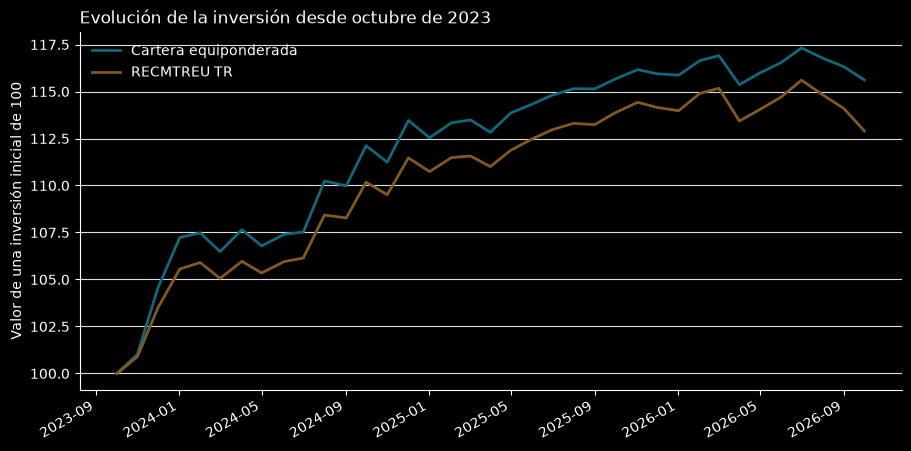

In [122]:
rent_mensual = backtest_cartera.set_index("Fecha Mes")[
    ["Rent cartera", "Rent benchmark"]
].rename(columns={"Rent cartera": "Cartera equiponderada", "Rent benchmark": "RECMTREU TR"})

base_100 = evolucion_cartera.set_index("Fecha Mes")[
    ["Cartera base 100", "RECMTREU base 100"]
].set_axis(rent_mensual.columns, axis=1)
base_100.loc[pesos_cartera.index[0]] = 100.0
base_100 = base_100.sort_index()

meses = len(rent_mensual)
factor_acumulado = base_100.iloc[-1] / 100
caida_desde_maximo = 1 - base_100 / base_100.cummax()
metricas_ejercicio_5 = pd.DataFrame({
    "Rentabilidad acumulada (%)": 100 * (factor_acumulado - 1),
    "Rentabilidad anualizada (%)": 100 * (factor_acumulado ** (12 / meses) - 1),
    "Volatilidad anualizada (%)": 100 * rent_mensual.std() * sqrt(12),
    "Caída máxima (%)": 100 * caida_desde_maximo.max(),
})

diferencia_mensual = backtest_cartera["Dif"]
tracking_error = diferencia_mensual.std() * sqrt(12)
ratio_informacion = 12 * diferencia_mensual.mean() / tracking_error
metricas_activas = pd.DataFrame([{
    "Tracking error anualizado (%)": 100 * tracking_error,
    "Ratio de información": ratio_informacion,
    "Meses por delante": int(diferencia_mensual.gt(0).sum()),
    "Meses observados": meses,
}])

display(metricas_ejercicio_5.round(2))
display(metricas_activas.round(2))

fig, ax = plt.subplots(figsize=(9, 4.4), layout="constrained")
base_100.plot(ax=ax, color=["#126778", "#825923"], linewidth=2)
ax.set_title("Evolución de la inversión desde octubre de 2023", loc="left")
ax.set_ylabel("Valor de una inversión inicial de 100")
ax.set_xlabel("")
ax.grid(axis="y", color="#dcdfe2", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.show()

Para hacer una mejor valoración se debería hacer el cálculo haciendo las compras en base al ask y ventas en base al bid, la horquilla no se está teniendo en cuenta al usar el MID por lo que se puede ver sobrevalorado el resultado de la cartera, algo que se ve incrementado por el rebalanceo.
Dentro de los datos proporcionados, utilizaríamos ITRAXX Main como referencia complementaria para analizar el riesgo de crédito, dado el predominio de bonos investment grade. Teniendo en cuenta otras opciones fuera de los datos del proyecto podríamos valorar el `Bloomberg Euro Aggregate Corporate Total Return (LECPTREU)`
El RECMTREU excluye emisores por actividad: alcohol, tabaco, juego, nuclear, armas. Y por controversias ESG graves. Nuestro `universo.csv` no tiene esos filtros, así que un benchmark más comparable sería el Bloomberg Euro Aggregate Corporate TR (o el ICE BofA Euro Corporate). Aun así, ninguno replica del todo el universo: ambos excluyen cupones variables, emisiones sin grado de inversión y perpetuos a tipo fijo, y ponderan por valor de mercado. Para la parte sin grado de inversión podría combinarse con un índice high yield en euros.

#### Resultado del backtest

En los 36 periodos mensuales, la cartera acumula un **15,62 %** frente al **12,90 %** del RECMTREU Total Return. La diferencia acumulada es de **2,71 puntos porcentuales**. La rentabilidad anualizada es del **4,96 %** para la cartera y del **4,13 %** para el índice. La cartera queda por delante en **19 de los 36 meses**.

La volatilidad anualizada es del **3,65 %** para la cartera y del **3,20 %** para el índice. La caída máxima en cierres mensuales es del **1,45 %** para la cartera y del **2,34 %** para el índice. El tracking error anualizado es del **0,80 %** y el ratio de información es **1,01**.

El resultado describe este periodo y este universo. La diferencia puede recoger cambios de composición, duración y calidad crediticia respecto al índice. Los precios MID, los cupones estimados y la ausencia de un universo histórico completo limitan la interpretación de la ventaja observada.

### <font color=#336699>6. Cartera mandato</font>

Tienes el mandato de **construir una cartera** de como máximo **20** bonos corporativos con ese universo y una serie de restricciones y, claro, maximizando la rentabilidad total de la cartera:
- La duración de la cartera no debe superar los 3 años
- La exposición a emisiones HY no puede superar el 10% de la cartera
- No puedes invertir en deuda subordinada
- No se puede invertir en emisiones de tamaño igual o inferior a 500 millones
- No se puede invertir más de un 10% del capital en una misma emisión
- No puede haber más de un 15% de concentración en un mismo emisor
(¡OJO! No estamos teniendo en cuenta en este ejercicio si hubiera un mínimo de inversión, lo cuál sería un dato relevante tener en cuenta en un caso real)

1. Constrúyela a fecha 1/10/2026

2. Teniendo en cuenta la naturaleza que nos están pidiendo para la cartera, ¿añadirías alguna otra restricción?

3. ¿Cómo medirías el riesgo de crédito de la cartera?

4. ¿Cómo medirías el riesgo de liquidez de la cartera? ¿Se te ocurre alguna otra información que se podría utilizar aunque no se te haya dado?

5. Describe cómo habría que hacer el backtest de esta cartera (no hace falta que lo implementes en este caso).


**Guarda en "results" una tabla llamada "cartera_optima.csv" que contenga:**

- ISIN
- Peso
- Yield
- Duration
- Rating
- Issuer
- Outstanding Amount
- Seniority
- Industry Sector

Y UNA FILA CON ISIN "CARTERA" CON LA DURACIÓN Y LA YIELD DE LA CARTERA RESULTANTE

In [123]:
salida_apartado_6 = carpeta_apartado(6)

# Segundo escenario: amortización a vencimiento, excluyendo los perpetuos.
vencimientos = pd.to_datetime(universo["Maturity"], dayfirst=True)
universo_sin_call = universo.loc[vencimientos.gt(fecha_analisis)].copy()
universo_sin_call["CallPrevia"] = False
sensibilidad_sin_call = results_yield.set_index("ISIN")[["Yield", "Dur"]].copy()

# Recalculamos únicamente los callable; los demás conservan sus cálculos anteriores.
for _, bono in universo_sin_call.loc[universo_sin_call["Callable"].eq("Y")].iterrows():
    bono = bono.copy()
    bono["Callable"] = "N"
    # Solo necesitamos calendario y cupón corrido para la TIR de mercado.
    # Los factores unitarios permiten obtener todos los flujos hasta vencimiento.
    curva_calendario = pd.DataFrame({
        "fecha": [fecha_analisis, pd.to_datetime(bono["Maturity"], dayfirst=True)],
        "factor_descuento": [1.0, 1.0],
    })
    _, _, corrido, flujos = valoracion_bono(bono, curva_calendario, fecha_analisis)
    frecuencia = int(bono["Coupon Frequency"])
    y = funciones_aux.calcular_yield(flujos, bono["Price"] + corrido, frecuencia)
    duracion, _, _ = funciones_aux.calcular_sensibilidad(flujos, y, frecuencia)
    sensibilidad_sin_call.loc[bono["ISIN"]] = [y, duracion]

escenarios = {
    "Con calls": (universo, results_yield, "cartera_optima.csv"),
    "Sin calls": (universo_sin_call, sensibilidad_sin_call.reset_index(), "cartera_optima_sin_calls.csv"),
}
carteras = {}
for nombre, (datos, sensibilidad, archivo) in escenarios.items():
    candidatos = candidatos_mandato(datos, sensibilidad, fecha_analisis)
    pesos = optimizar_mandato(candidatos)
    posiciones_escenario = candidatos.loc[pesos.index].assign(Peso=pesos)
    carteras[nombre] = posiciones_escenario
    tabla = posiciones_escenario.rename(columns={"Dur": "Duration"})[
        ["Peso", "Yield", "Duration", "Rating", "Issuer", "Outstanding Amount",
         "Seniority", "Industry Sector"]
    ].copy()
    tabla.loc["CARTERA", ["Peso", "Yield", "Duration"]] = [
        pesos.sum(), pesos.dot(tabla["Yield"]), pesos.dot(tabla["Duration"])
    ]
    tabla.to_csv(salida_apartado_6 / archivo)
    print(nombre)
    display(tabla)

# Variables de la cartera original para los apartados posteriores.
posiciones = carteras["Con calls"]
pesos_mandato = posiciones["Peso"]


Con calls


,Peso,Yield,Duration,Rating,Issuer,Outstanding Amount,Seniority,Industry Sector
ISIN,,,,,,,,
FR0013201639,0.1,0.237884,0.032877,AA-,SANOFI SA,1.150000e+09,Sr Unsecured,"Consumer, Non-cyclical"
FR0013217114,0.1,0.090837,0.090411,BBB+,ORANGE SA,7.500000e+08,Sr Unsecured,Communications
FR0013231099,0.1,0.128045,0.046575,A-,AUTOROUTES DU SUD DE LA,1.000000e+09,Sr Unsecured,"Consumer, Non-cyclical"
FR0013231768,0.1,0.166011,0.038356,BBB-,IMERYS SA,6.000000e+08,Sr Unsecured,Industrial
FR0013238045,0.1,0.067599,0.126027,A-,KLEPIERRE SA,6.000000e+08,Sr Unsecured,Financial
FR0013405032,0.1,0.067239,0.156164,BBB,UNIBAIL-RODAMCO-WESTFLD,7.500000e+08,Sr Unsecured,Financial
FR0014001I50,0.1,0.258236,0.035616,BBB,VEOLIA ENVIRONNEMENT SA,7.000000e+08,Sr Unsecured,Utilities
XS1319820541,0.1,0.170191,0.027397,BBB,FEDEX CORP,1.250000e+09,Sr Unsecured,Industrial
XS1756296965,0.1,0.099109,0.057534,BBB-,TELEFONICA EMISIONES SAU,1.000000e+09,Sr Unsecured,Communications


Sin calls


,Peso,Yield,Duration,Rating,Issuer,Outstanding Amount,Seniority,Industry Sector
ISIN,,,,,,,,
CH1214797172,0.100000,0.051287,2.213135,A-,UBS GROUP AG,3.000000e+09,Sr Unsecured,Financial
FR0010014845,0.100000,0.056312,5.901611,BBB,PSA TRESORERIE GIE,6.000000e+08,Sr Unsecured,"Consumer, Cyclical"
FR001400M2G2,0.100000,0.052045,4.397697,NR,TELEPERFORMANCE,7.000000e+08,Sr Unsecured,Technology
IT0005549479,0.100000,0.049795,1.647859,BBB-,BANCO BPM SPA,7.500000e+08,Sr Non Preferred,Financial
XS2464732770,0.100000,0.055788,5.079563,BBB,STELLANTIS NV,1.000000e+09,Sr Unsecured,"Consumer, Cyclical"
XS2489775580,0.100000,0.047476,2.187998,BBB-,SES SA,7.500000e+08,Sr Unsecured,Communications
XS2554746185,0.100000,0.046782,1.074147,A-,ING GROEP NV,1.250000e+09,Sr Unsecured,Financial
XS2555420103,0.100000,0.055549,1.068166,BBB,UNICREDIT SPA,1.000000e+09,Sr Non Preferred,Financial
XS2679904768,0.100000,0.050500,2.758383,BBB-,BANCO DE CREDITO SOCIAL,6.500000e+08,Sr Preferred,Financial


En cuanto a las restricciones que se podrían aplicar destacamos:
- Límite por sector (máx. 25-30 %). La cartera sin calls tiene un 52,6 % en financieras.
- Límite al tramo BBB− y sin rating (máx. ~20 %), por el riesgo de fallen angel: ahora suman un 42 %.
- Liquidez: horquilla máxima de unos 50 pb y un tope sobre el nominal vivo de cada emisión. PSA llega a 84 pb.

##### <font color=#CC6600>Riesgo de crédito</font>

Las dos carteras maximizan la yield ponderada con duración de Macaulay máxima de tres años. En el segundo escenario se supone que todos los bonos con vencimiento futuro permanecen vivos hasta esa fecha, incluyendo los que el primer escenario marcaba como rescatados por call. Los perpetuos quedan excluidos. La elección de valorar a vencimiento cambia las yields y la selección, pero el máximo de veinte emisiones permite soluciones de diez bonos.

Medimos el riesgo de crédito mediante la distribución del rating ya que un porcentaje alto de nuestra cartera tiene bonos con rating BBB-(cartera sin calls) que está muy cercana al margen de convertirse en un fallen angel. Concentración por emisor, grupo y sector.

In [124]:
for nombre, cartera in carteras.items():
    print(nombre)
    display(cartera.groupby("Rating")["Peso"].sum().to_frame("Peso"))
    display(pd.Series({
        "Peso HY y sin rating": cartera.loc[~cartera["Rating"].isin(RATINGS_IG), "Peso"].sum(),
        "Mayor peso por emisor": cartera.groupby("Issuer")["Peso"].sum().max(),
        "PD ponderada (unidad del proveedor)": cartera["Peso"].dot(cartera["PD 1YR"]),
    }))


Con calls


,Peso
Rating,
A-,0.2
AA-,0.1
BBB,0.3
BBB+,0.1
BBB-,0.3


Peso HY y sin rating                   0.000000
Mayor peso por emisor                  0.100000
PD ponderada (unidad del proveedor)    0.004274
dtype: float64

Sin calls


,Peso
Rating,
A-,0.200000
BBB,0.376224
BBB-,0.323776
NR,0.100000


Peso HY y sin rating                   0.100000
Mayor peso por emisor                  0.150000
PD ponderada (unidad del proveedor)    0.007693
dtype: float64

##### <font color=#CC6600>Riesgo de liquidez</font>

Medimos el coste indicativo de negociación con la horquilla bid-ask relativa, ponderada por el valor de cada posición. Además tenemos en cuenta el importe vivo de cada emisión (nominal en circulación): una emisión mayor tiene más inversores y más negociación, por lo que suele ser más líquida. Lo relevante es comparar el nominal de nuestra posición con ese importe vivo.
Para mejorar el análisis convendría disponer del volumen diario negociado para estimar los días necesarios para liquidar una posición y el comportamiento de la horquilla de precios en momentos de estrés.

In [125]:
for nombre, cartera in carteras.items():
    horquilla = (cartera["Ask Price"] - cartera["Bid Price"]) / cartera["Price"]
    print(nombre)
    display(pd.Series({
        "Horquilla ponderada (pb)": 10_000 * cartera["Peso"].dot(horquilla),
        "Menor importe vivo (millones EUR)": cartera["Outstanding Amount"].min() / 1e6,
    }))


Con calls


Horquilla ponderada (pb)               8.0145
Menor importe vivo (millones EUR)    600.0000
dtype: float64

Sin calls


Horquilla ponderada (pb)              27.983155
Menor importe vivo (millones EUR)    600.000000
dtype: float64

##### <font color=#CC6600>Backtest</font>

Construimos ambas carteras a 01/10/2026, la última fecha de los datos. Para el backtest simularíamos qué habría pasado si hubiéramos gestionado la cartera con este mismo mandato durante todo el periodo del histórico de precios, de octubre de 2023 a octubre de 2026. El proceso sería mensual:

En la primera fecha (octubre de 2023) construiríamos la cartera óptima con los bonos vivos, sus precios, ratings, yields y duraciones de ese día. No usaríamos ningún dato posterior, porque en ese momento no se conocía.
Mantendríamos la cartera durante un mes y calcularíamos su rentabilidad con los precios, cupones y amortizaciones de ese periodo. En el escenario con calls incorporaríamos los rescates ejecutados. En el escenario sin calls supondríamos amortización a vencimiento.
Al mes siguiente repetiríamos el proceso con la nueva información, hasta llegar a octubre de 2026.

Entre rebalanceos comprobaríamos todas las restricciones del mandato (duración máxima de tres años, límite HY, concentración por emisión y emisor). Si alguna se incumpliera, por ejemplo por una rebaja de rating, rebalancearíamos antes de fin de mes. Para recoger el coste de negociar, compraríamos al precio ask y venderíamos al bid en lugar de usar el MID.

Utilizaríamos **RECMTREU Total Return** como benchmark porque su histórico está disponible en precios_historicos_varios.csv y permite comparar rentabilidades incluyendo los cupones. Compararíamos ambas series en base 100 y mediríamos rentabilidad acumulada y anualizada, volatilidad, caída máxima, tracking error, ratio de información y rotación. 

Como alternativa, podrían considerarse índices externos de bonos corporativos en euros, lo que permitiría reducir las diferencias de riesgo entre cartera y benchmark. **RECMTREU** aplica además filtros ESG que nuestro universo no tiene, por lo que su versión sin filtros, el **Bloomberg Euro Aggregate Corporate**, sería más comparable.

La principal limitación es que no disponemos de todos los datos históricos que este proceso necesita. universo.csv recoge los ratings y características de los bonos a 01/10/2026, no los que tenían en cada fecha pasada, y solo incluye bonos vivos ese día. Faltan los bonos que vencieron o fueron rescatados durante el periodo, que sí habrían podido formar parte de la cartera. Usar solo los bonos que han sobrevivido haría que el resultado pareciera mejor de lo que habría sido (sesgo de supervivencia).


### <font color=#336699>7. Cobertura tipos de interés</font>

**Cubre la exposición de la cartera a los tipos de interés.**

Utiliza alguno de los siguientes instrumentos para cubrir la duración (sensibilidad de tipos de interés) de la cartera que has construido según el mandato. Asume una inversión en la cartera de 10 millones:

- Futuros sobre el *Schatz* (ticker: DU1) - Duración a 01/10/2026: 1.92
- Futuros sobre el *BOBL* (ticker: OE1) - Duración a 01/10/2026: 5.44
- Futuros sobre el *BUND* (ticker: RX1) - Duración a 01/10/2026: 10

*Contract size* en todos los casos: 100,000 euros

Investiga sobre estos instrumentos antes de tomar la decisión. Razona tu elección del instrumento y el número de contratos que has decidido comprar/vender.

- ¿Qué pasaría si comprásemos/vendiésemos 100 futuros?
- ¿Se te ocurre algún otro instrumento con el que cubrir la sensibilidad a los tipos de interés de la cartera?


In [126]:
salida_apartado_7 = carpeta_apartado(7)

# Aproximación de primer orden para una inversión de 10 millones por escenario.
capital_cobertura = 10_000_000
futuros = pd.DataFrame({
    "Futuro": ["Schatz", "BOBL", "BUND"],
    "DuracionFuturo": [1.92, 5.44, 10.0],
}, index=["DU1 Comdty", "OE1 Comdty", "RX1 Comdty"])
futuros["PrecioFuturo"] = historicos_varios.loc[fecha_analisis, futuros.index]
if not futuros["PrecioFuturo"].gt(0).all():
    raise ValueError("Falta una cotización positiva de futuros en la fecha de cobertura.")

# La cotización está expresada por 100 de nominal. Cada contrato tiene nominal 100.000.
futuros["PVBPContrato"] = (
    futuros["DuracionFuturo"] * 100_000 * futuros["PrecioFuturo"] / 100 * 1e-4
)
coberturas = []
for nombre, cartera in carteras.items():
    # Reutilizamos Macaulay y yield del escenario correspondiente.
    mod_dur = cartera["Dur"] / (1 + cartera["Yield"] / cartera["Coupon Frequency"])
    mod_dur_cartera = cartera["Peso"].dot(mod_dur)
    pvbp_cartera = capital_cobertura * mod_dur_cartera * 1e-4
    cobertura = futuros.copy()
    cobertura["Escenario"] = nombre
    cobertura["ModDurCartera"] = mod_dur_cartera
    cobertura["PVBPCartera"] = pvbp_cartera
    cobertura["ContratosTeoricosVenta"] = pvbp_cartera / cobertura["PVBPContrato"]
    cobertura["ContratosVenta"] = cobertura["ContratosTeoricosVenta"].round().astype(int)
    cobertura["PVBPResidual"] = (
        pvbp_cartera - cobertura["ContratosVenta"] * cobertura["PVBPContrato"]
    )
    # P&L conjunto ante una subida de 1 pb. El signo positivo significa ganancia.
    cobertura["PLSubida1pbCubierta"] = -cobertura["PVBPResidual"]
    cobertura["PLSubida1pbVenta100"] = -pvbp_cartera + 100 * cobertura["PVBPContrato"]
    cobertura["PLSubida1pbCompra100"] = -pvbp_cartera - 100 * cobertura["PVBPContrato"]
    coberturas.append(cobertura)

resultado_cobertura = pd.concat(coberturas).reset_index(names="Ticker")
resultado_cobertura.to_csv(salida_apartado_7 / "cobertura_tipos.csv", index=False)
display(resultado_cobertura.set_index(["Escenario", "Futuro"]).round(4))

# Revaloramos con desplazamientos de yield atribuidos a tipos, con spreads constantes.
# Usamos el mismo descuento por frecuencia que en el cálculo de ModDur.

shocks_tipos = [-150, -100, -50, 50, 100, 150]
perdidas_tipos = {}
for nombre, cartera in carteras.items():
    valores_escenarios = {shock: 0.0 for shock in shocks_tipos}
    for isin, bono in cartera.iterrows():
        if nombre == "Sin calls" and bono["Callable"] == "Y":
            bono_calendario = bono.copy()
            bono_calendario["Callable"] = "N"
            curva_calendario = pd.DataFrame({
                "fecha": [fecha_analisis, pd.to_datetime(bono["Maturity"], dayfirst=True)],
                "factor_descuento": [1.0, 1.0],
            })
            _, _, _, flujos = valoracion_bono(bono_calendario, curva_calendario, fecha_analisis)
        else:
            flujos = flujos_por_isin[isin]
        frecuencia = int(bono["Coupon Frequency"])
        periodos = frecuencia * flujos["plazo"]
        precio_base = (flujos["flujo_total"] / (1 + bono["Yield"] / frecuencia) ** periodos).sum()
        unidades = capital_cobertura * bono["Peso"] / precio_base
        for shock in shocks_tipos:
            precio_shock = (
                flujos["flujo_total"] / (1 + (bono["Yield"] + shock / 10_000) / frecuencia) ** periodos
            ).sum()
            valores_escenarios[shock] += unidades * precio_shock
    for shock, valor in valores_escenarios.items():
        perdidas_tipos[nombre, shock] = capital_cobertura - valor

# Cada alternativa fija sus contratos antes del shock.
comparaciones_tipos = []
for fila in resultado_cobertura.itertuples():
    for porcentaje in [0, 25, 50, 75, 100]:
        contratos = round(porcentaje / 100 * fila.PVBPCartera / fila.PVBPContrato)
        efectivo_pct = 100 * contratos * fila.PVBPContrato / fila.PVBPCartera
        residual = fila.PVBPCartera - contratos * fila.PVBPContrato
        for shock in shocks_tipos:
            pl_bonos = -perdidas_tipos[fila.Escenario, shock]
            pl_futuros = contratos * fila.PVBPContrato * shock
            comparaciones_tipos.append({
                "Escenario": fila.Escenario, "Futuro": fila.Futuro,
                "ShockPb": shock, "CoberturaObjetivoPct": porcentaje,
                "CoberturaEfectivaPct": efectivo_pct, "ContratosVenta": contratos,
                "PVBPResidual": residual, "PLBonos": pl_bonos,
                "PLFuturosAprox": pl_futuros, "PLConjunto": pl_bonos + pl_futuros,
                "PLConjuntoPct": 100 * (pl_bonos + pl_futuros) / capital_cobertura,
            })
comparacion_cobertura_tipos = pd.DataFrame(comparaciones_tipos)
comparacion_cobertura_tipos.to_csv(
    salida_apartado_7 / "comparacion_cobertura_tipos.csv", index=False
)
# Solo mostramos la cartera sin calls: con 71 €/pb, la de calls se cubre con 0-4 contratos
# y el porcentaje efectivo lo decide el redondeo. El detalle completo queda en el CSV.
# La tabla apoya dos decisiones: ante movimientos paralelos los tres futuros dan casi
# el mismo resultado (no sirve para elegir entre ellos) y muestra qué deja cada porcentaje.
print("Sin calls - P&L conjunto en euros por futuro, shock paralelo y % de cobertura")
display(comparacion_cobertura_tipos.loc[comparacion_cobertura_tipos["Escenario"].eq("Sin calls")].pivot(
    index=["Futuro", "ShockPb"], columns="CoberturaObjetivoPct", values="PLConjunto"
).round(0))


Ticker  DuracionFuturo  PrecioFuturo  PVBPContrato  \
Escenario Futuro                                                           
Con calls Schatz  DU1 Comdty            1.92       104.925       20.1456   
          BOBL    OE1 Comdty            5.44       112.520       61.2109   
          BUND    RX1 Comdty           10.00       120.350      120.3500   
Sin calls Schatz  DU1 Comdty            1.92       104.925       20.1456   
          BOBL    OE1 Comdty            5.44       112.520       61.2109   
          BUND    RX1 Comdty           10.00       120.350      120.3500   

                  ModDurCartera  PVBPCartera  ContratosTeoricosVenta  \
Escenario Futuro                                                       
Con calls Schatz         0.0714      71.3964                  3.5440   
          BOBL           0.0714      71.3964                  1.1664   
          BUND           0.0714      71.3964                  0.5932   
Sin calls Schatz         2.8494    2849.4227                141.4414   
          BOBL           2.8494    2849.4227                 46.5509   
          BUND           2.8494    2849.4227                 23.6761   

                  ContratosVenta  PVBPResidual  PLSubida1pbCubierta  \
Escenario Futuro                                                      
Con calls Schatz               4       -9.1860               9.1860   
          BOBL                 1       10.1856             -10.1856   
          BUND                 1      -48.9536              48.9536   
Sin calls Schatz             141        8.8931              -8.8931   
          BOBL                47      -27.4887              27.4887   
          BUND                24      -38.9773              38.9773   

                  PLSubida1pbVenta100  PLSubida1pbCompra100  
Escenario Futuro                                             
Con calls Schatz            1943.1636            -2085.9564  
          BOBL              6049.6916            -6192.4844  
          BUND             11963.6036           -12106.3964  
Sin calls Schatz            -834.8627            -4863.9827  
          BOBL              3271.6653            -8970.5107  
          BUND              9185.5773           -14884.4227

Sin calls - P&L conjunto en euros por futuro, shock paralelo y % de cobertura


CoberturaObjetivoPct       0         25        50        75       100
Futuro ShockPb                                                       
BOBL   -150           443803.0  333623.0  232625.0  122446.0  12266.0
       -100           292145.0  218692.0  151360.0   77907.0   4454.0
       -50            144252.0  107526.0   73860.0   37133.0    407.0
        50           -140729.0 -104002.0  -70336.0  -33610.0   3117.0
        100          -278047.0 -204594.0 -137262.0  -63809.0   9644.0
        150          -412065.0 -301885.0 -200887.0  -90708.0  19472.0
BUND   -150           443803.0  335488.0  227173.0  118858.0  10543.0
       -100           292145.0  219935.0  147725.0   75515.0   3305.0
       -50            144252.0  108147.0   72042.0   35937.0   -168.0
        50           -140729.0 -104624.0  -68519.0  -32414.0   3691.0
        100          -278047.0 -205837.0 -133627.0  -61417.0  10793.0
        150          -412065.0 -303750.0 -195435.0  -87120.0  21195.0
Schatz -150           443803.0  338038.0  229252.0  123488.0  17723.0
       -100           292145.0  221636.0  149112.0   78602.0   8092.0
       -50            144252.0  108997.0   72735.0   37480.0   2226.0
        50           -140729.0 -105474.0  -69212.0  -33957.0   1298.0
        100          -278047.0 -207538.0 -135014.0  -64504.0   6006.0
        150          -412065.0 -306300.0 -197514.0  -91750.0  14015.0

Elección: vender Schatz y BOBL para cubrir el 75 % del PVBP de su tramo


PVBPTramo  PesoTramoPct  ContratosVenta  PVBPCubierto  \
Escenario Futuro                                                          
Con calls Schatz      71.40        100.00               3         60.44   
          BOBL         0.00          0.00               0          0.00   
          BUND         0.00          0.00               0          0.00   
Sin calls Schatz    1159.14         40.68              43        866.26   
          BOBL      1690.28         59.32              21       1285.43   
          BUND         0.00          0.00               0          0.00   

                  CoberturaEfectivaPct  CapitalReferencia  
Escenario Futuro                                           
Con calls Schatz                 84.65           10000000  
          BOBL                     NaN           10000000  
          BUND                     NaN           10000000  
Sin calls Schatz                 74.73           10000000  
          BOBL                   76.05           10000000  
          BUND                     NaN           10000000

Cartera sin calls: P&L en euros ante cada movimiento de la curva


,Sin cobertura,Solo Schatz (106 contratos),Schatz + BOBL por tramos
Subida paralela de 100 pb,-284942.0,-71399.0,-69773.0
Sube 20 pb el tramo corto,-23183.0,19526.0,-5858.0
Sube 20 pb el tramo medio,-33806.0,-33806.0,-8097.0


Eficacia histórica, 149 semanas desde 24/11/2023


,Volatilidad semanal (€),Reducción de volatilidad (%)
Sin cobertura,47758.4,0.0
Solo Schatz (106 contratos),37354.1,21.8
Schatz + BOBL por tramos,37201.9,22.1


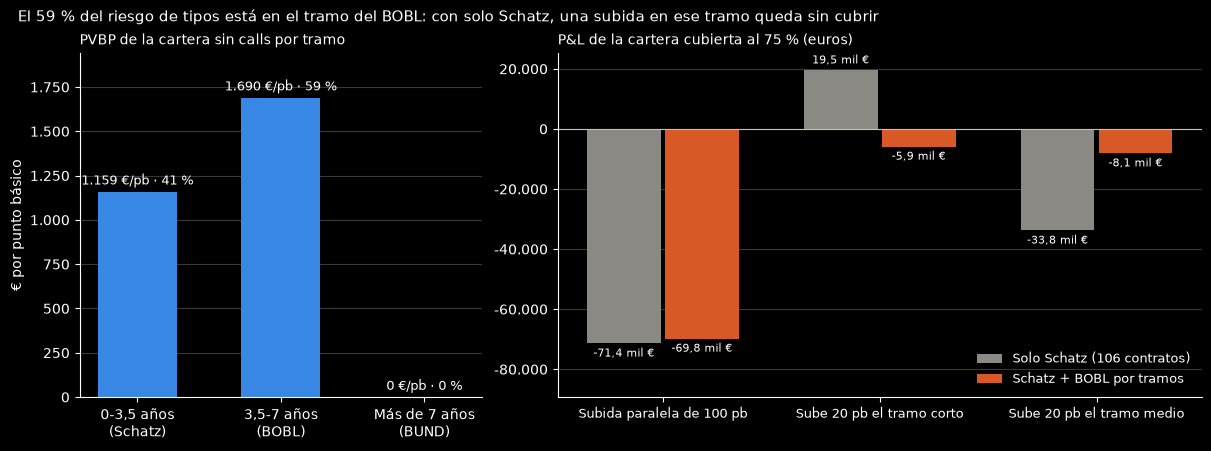

In [127]:
# Cobertura por tramos: repartimos el PVBP de la cartera según el plazo de cada flujo
# y cubrimos cada tramo con el futuro cuyo subyacente está en ese plazo.
# Entregables de Eurex: Schatz 1,75-2,25 años, BOBL 4,5-5,5 años, BUND 8,5-10,5 años.
tramos = pd.DataFrame({
    "Tramo": ["0-3,5 años", "3,5-7 años", "Más de 7 años"],
    "Futuro": ["Schatz", "BOBL", "BUND"],
    "Hasta": [3.5, 7.0, float("inf")],
})
pvbp_contrato = futuros.set_index("Futuro")["PVBPContrato"]


def pvbp_por_tramo(nombre, cartera):
    """PVBP en euros por punto básico de cada tramo, con 10 millones invertidos."""
    pvbp = pd.Series(0.0, index=tramos["Futuro"])
    for isin, bono in cartera.iterrows():
        # Mismos flujos que en la revaloración anterior: sin calls, hasta vencimiento.
        if nombre == "Sin calls" and bono["Callable"] == "Y":
            bono_calendario = bono.copy()
            bono_calendario["Callable"] = "N"
            curva_calendario = pd.DataFrame({
                "fecha": [fecha_analisis, pd.to_datetime(bono["Maturity"], dayfirst=True)],
                "factor_descuento": [1.0, 1.0],
            })
            _, _, _, flujos = valoracion_bono(bono_calendario, curva_calendario, fecha_analisis)
        else:
            flujos = flujos_por_isin[isin]
        frecuencia = int(bono["Coupon Frequency"])
        valor_flujos = flujos["flujo_total"] / (1 + bono["Yield"] / frecuencia) ** (
            frecuencia * flujos["plazo"]
        )
        unidades = capital_cobertura * bono["Peso"] / valor_flujos.sum()
        # Contribución de cada flujo a la duración modificada, en euros por pb.
        pvbp_flujos = unidades * valor_flujos * flujos["plazo"] / (1 + bono["Yield"] / frecuencia) * 1e-4
        tramo_flujo = pd.cut(
            flujos["plazo"], bins=[0, *tramos["Hasta"]], labels=tramos["Futuro"], right=False
        )
        pvbp = pvbp.add(pvbp_flujos.groupby(tramo_flujo, observed=False).sum(), fill_value=0)
    return pvbp


# Elección: vender en cada tramo los contratos que cubren el 75 % de su PVBP.
porcentaje_cobertura_tipos = 0.75
filas_eleccion = []
pvbp_tramos = {}
for nombre, cartera in carteras.items():
    pvbp_tramos[nombre] = pvbp_por_tramo(nombre, cartera)
    for futuro, pvbp in pvbp_tramos[nombre].items():
        contratos = round(porcentaje_cobertura_tipos * pvbp / pvbp_contrato[futuro])
        filas_eleccion.append({
            "Escenario": nombre, "Futuro": futuro, "PVBPTramo": pvbp,
            "PesoTramoPct": 100 * pvbp / pvbp_tramos[nombre].sum(),
            "ContratosVenta": contratos,
            "PVBPCubierto": contratos * pvbp_contrato[futuro],
        })
cobertura_tipos_elegida = pd.DataFrame(filas_eleccion)
cobertura_tipos_elegida["CoberturaEfectivaPct"] = (
    100 * cobertura_tipos_elegida["PVBPCubierto"] / cobertura_tipos_elegida["PVBPTramo"]
)
cobertura_tipos_elegida["CapitalReferencia"] = capital_cobertura
cobertura_tipos_elegida.to_csv(salida_apartado_7 / "cobertura_tipos_elegida.csv", index=False)
print("Elección: vender Schatz y BOBL para cubrir el 75 % del PVBP de su tramo")
display(cobertura_tipos_elegida.set_index(["Escenario", "Futuro"]).round(2))

# Escenarios de curva: shocks en pb por tramo. P&L lineal con PVBP constante.
escenarios_curva = pd.DataFrame({
    "Schatz": [100, 20, 0],
    "BOBL": [100, 0, 20],
    "BUND": [100, 0, 20],
}, index=["Subida paralela de 100 pb", "Sube 20 pb el tramo corto", "Sube 20 pb el tramo medio"])
contratos_solo_schatz = round(
    porcentaje_cobertura_tipos * pvbp_tramos["Sin calls"].sum() / pvbp_contrato["Schatz"]
)
alternativas = {
    "Sin cobertura": pd.Series(0, index=tramos["Futuro"]),
    f"Solo Schatz ({contratos_solo_schatz} contratos)": pd.Series(
        {"Schatz": contratos_solo_schatz, "BOBL": 0, "BUND": 0}
    ),
    "Schatz + BOBL por tramos": cobertura_tipos_elegida.loc[
        cobertura_tipos_elegida["Escenario"].eq("Sin calls")
    ].set_index("Futuro")["ContratosVenta"],
}
pl_curva = pd.DataFrame({
    alternativa: [
        -(pvbp_tramos["Sin calls"] * shock).sum() + (contratos * pvbp_contrato * shock).sum()
        for _, shock in escenarios_curva.iterrows()
    ]
    for alternativa, contratos in alternativas.items()
}, index=escenarios_curva.index)
pl_curva.to_csv(salida_apartado_7 / "cobertura_tipos_escenarios_curva.csv")
print("Cartera sin calls: P&L en euros ante cada movimiento de la curva")
display(pl_curva.round(0))

# Eficacia histórica: posiciones de hoy llevadas hacia atrás, P&L semanal en euros.
precios_semana = precios_mid_backtest.T.resample("W-FRI").last()
futuros_semana = historicos_varios[futuros.index].resample("W-FRI").last()
cartera_sin_calls = carteras["Sin calls"]
nominal = capital_cobertura * cartera_sin_calls["Peso"] / (cartera_sin_calls["Price"] / 100)
datos = pd.concat([precios_semana[cartera_sin_calls.index], futuros_semana], axis=1).dropna()
# Precio limpio: dejamos fuera el devengo del cupón, que no depende de los tipos.
pl_cartera = datos[cartera_sin_calls.index].diff().mul(nominal / 100).sum(axis=1).iloc[1:]
# Cada punto de precio del futuro vale 1.000 euros por contrato (100.000 / 100).
pl_futuros = datos[futuros.index].diff().iloc[1:].set_axis(futuros["Futuro"], axis=1) * 1_000
eficacia = {}
for alternativa, contratos in alternativas.items():
    pl_cubierto = pl_cartera - pl_futuros.mul(contratos.reindex(pl_futuros.columns, fill_value=0)).sum(axis=1)
    eficacia[alternativa] = {
        "Volatilidad semanal (€)": pl_cubierto.std(),
        "Reducción de volatilidad (%)": 100 * (1 - pl_cubierto.std() / pl_cartera.std()),
    }
eficacia_historica = pd.DataFrame(eficacia).T
eficacia_historica.to_csv(salida_apartado_7 / "eficacia_historica_cobertura.csv")
print(f"Eficacia histórica, {len(pl_cartera)} semanas desde {datos.index[0]:%d/%m/%Y}")
display(eficacia_historica.round(1))

# Gráfico: dónde está el riesgo y qué deja sin cubrir cada alternativa.
# Colores pensados para el estilo dark_background del cuaderno.
azul, naranja, gris = "#3987e5", "#d95926", "#8a8983"
fig, (eje_tramos, eje_pl) = plt.subplots(
    1, 2, figsize=(12, 4.4), layout="constrained", gridspec_kw={"width_ratios": [1, 1.6]}
)
pvbp_grafico = pvbp_tramos["Sin calls"]
barras = eje_tramos.bar(
    [f"{t}\n({f})" for t, f in zip(tramos["Tramo"], tramos["Futuro"])],
    pvbp_grafico.values, color=azul, width=0.55,
)
eje_tramos.bar_label(barras, labels=[
    f"{v:,.0f} €/pb · {100 * v / pvbp_grafico.sum():.0f} %".replace(",", ".") for v in pvbp_grafico
], padding=3, fontsize=9)
eje_tramos.set_title("PVBP de la cartera sin calls por tramo", loc="left", fontsize=10)
eje_tramos.set_ylabel("€ por punto básico")

anchura = 0.36
posiciones_x = range(len(pl_curva))
columnas_grafico = [c for c in pl_curva.columns if c != "Sin cobertura"]
for k, (columna, color) in enumerate(zip(columnas_grafico, [gris, naranja])):
    barras = eje_pl.bar(
        [x + (k - 0.5) * anchura for x in posiciones_x], pl_curva[columna],
        width=anchura - 0.02, color=color, label=columna,
    )
    eje_pl.bar_label(barras, labels=[f"{v / 1000:,.1f} mil €".replace(".", ",") for v in pl_curva[columna]],
                     padding=3, fontsize=8)
eje_pl.axhline(0, color="#c3c2b7", linewidth=0.8)
eje_pl.set_xticks(list(posiciones_x), pl_curva.index, fontsize=9)
eje_pl.set_ylim(1.25 * pl_curva[columnas_grafico].min().min(), 1.3 * max(pl_curva[columnas_grafico].max().max(), 0))
eje_pl.set_title("P&L de la cartera cubierta al 75 % (euros)", loc="left", fontsize=10)
eje_pl.legend(frameon=False, fontsize=9, loc="lower right")
for eje in (eje_tramos, eje_pl):
    eje.spines[["top", "right"]].set_visible(False)
    eje.grid(axis="y", color="#383835", linewidth=0.8)
    eje.set_axisbelow(True)
    eje.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
eje_tramos.set_ylim(0, 1.15 * pvbp_grafico.max())
peso_bobl = 100 * pvbp_grafico["BOBL"] / pvbp_grafico.sum()
fig.suptitle(
    f"El {peso_bobl:.0f} % del riesgo de tipos está en el tramo del BOBL: "
    "con solo Schatz, una subida en ese tramo queda sin cubrir",
    x=0.01, ha="left", fontsize=11,
)
plt.show()

**Cálculo.** Vendemos futuros hasta igualar el PVBP de la cartera: si suben los tipos, la cartera pierde y los futuros vendidos ganan. PVBP de la cartera = capital × ModDur ponderada × 0,0001, con ModDur = Dur / (1 + Yield / frecuencia). PVBP por contrato = duración del enunciado × 100.000 × precio / 100 × 0,0001. Contratos = PVBP cubierto / PVBP por contrato, redondeado.

Con 10 millones, la cartera sin calls tiene un PVBP de **2.849 €/pb** (1.159 en el tramo de 0 a 3,5 años y 1.690 en el de 3,5 a 7) y la de calls, **71 €/pb**. Cada contrato cubre 20,15 €/pb (Schatz), 61,21 (BOBL) y 120,35 (BUND). Cubrir el 100 % de la cartera sin calls con un solo futuro exigiría 141 Schatz, 47 BOBL o 24 BUND; nuestra cobertura vende **43 Schatz** (0,75 × 1.159 / 20,15) y **21 BOBL** (0,75 × 1.690 / 61,21). La cartera con calls necesitaría 3,5 Schatz para el 100 % y vendemos **3**.

**Elección del instrumento.** La tabla de la cartera sin calls muestra que, ante movimientos paralelos, los tres futuros cubren casi lo mismo, porque cada uno se dimensiona para igualar el mismo PVBP. Lo que los diferencia es el tramo de la curva que replican: Schatz, 1,75-2,25 años; BOBL, 4,5-5,5 años. El 41 % del PVBP de la cartera sin calls está entre 0 y 3,5 años y el 59 % entre 3,5 y 7, así que vendemos **Schatz y BOBL en proporción a cada tramo**, al 75 %: 43 Schatz y 21 BOBL.

Ante +100 pb paralelos, el resultado es casi igual que vendiendo 106 Schatz (−69.773 € frente a −71.399 €). Si sube 20 pb solo el tramo medio, con solo Schatz se pierden 33.806 €, como sin cobertura, y con la combinación 8.097 €. Si sube solo el tramo corto, vender solo Schatz gana 19.526 €: eso ya es una apuesta sobre la curva, no una cobertura. En el histórico, ambas alternativas reducen la volatilidad semanal del P&L en torno a un 22 %; el resto viene sobre todo de los spreads de crédito (apartado 8).

La cartera con calls tiene todo su PVBP (71 €/pb) en el tramo corto: 3 Schatz, aunque la cobertura apenas aporta. Por eso no mostramos su tabla, en la que el redondeo decide el porcentaje; el detalle de ambas carteras está en comparacion_cobertura_tipos.csv.

**Resultado.** Por el redondeo, las coberturas efectivas son del 74,73 % (Schatz) y el 76,05 % (BOBL) en la cartera sin calls y del 84,65 % en la de calls. Cubrimos el 75 % para conservar parte de la ganancia si bajan los tipos, igual que en la cobertura de crédito del apartado 8. Con otro capital se recalcula desde el PVBP escalado, como en el apartado 9.

**¿Y con 100 futuros?** Vendidos, quedaríamos sobrecubiertos o infracubiertos según el futuro y la cartera; comprados, aumentaría la pérdida ante una subida de tipos.

**Otro instrumento.** Un swap de tipos pagando fijo y recibiendo variable, dimensionado por su PVBP.

### <font color=#336699>8. Cobertura crédito</font>

**Cubre total o parcialmente el riesgo de crédito.**

Utiliza alguno de los siguientes instrumentos para cubrir el riesgo de crédito de la cartera que has construido según el mandato. Asume una inversión en la cartera de 10 millones€:

- ITRAXX Main (ticker: ITRX EUR CDSI GEN 5Y Corp)
- ITRAXX XOVER (ticker: ITRX XOVER CDSI GEN 5Y Corp)

Estos índices cotizan en forma de spread, en puntos básicos. La sensibilidad del valor del CDS es de 4,500€ al punto básico, asumiendo una inversión de 10 millones€.

Investiga sobre estos instrumentos antes de tomar la decisión. Razona tu elección del instrumento y el nominal que has decidido comprar/vender.

- ¿Tiene sentido plantear esta cobertura total?
- ¿Con qué otros instrumentos podrías cubrir el riesgo de crédito?
- ¿Qué riesgos permanecen después de la cobertura? Menciona al menos 3 y razónalos.


In [128]:
salida_apartado_8 = carpeta_apartado(8)

capital_credito = 10_000_000
spreads_base = results_spread.set_index("ISIN")["Spread"]
valoraciones_base = results.set_index("ISIN")
perdidas_credito = []
shocks_credito = []
flujos_calibrados = {}

for nombre, cartera in carteras.items():
    for isin, bono in cartera.iterrows():
        # Recuperamos los flujos y el spread calculados cuando coinciden con el escenario.
        if nombre == "Sin calls" and bono["Callable"] == "Y":
            bono_sin_call = bono.copy()
            bono_sin_call["Callable"] = "N"
            limpio, _, corrido, flujos = valoracion_bono(
                bono_sin_call, curva_descuento, fecha_analisis
            )
            spread_pb, _ = funciones_aux.calcular_spread(
                flujos, bono["Price"], limpio, corrido
            )
        else:
            flujos = flujos_por_isin[isin]
            corrido = valoraciones_base.at[isin, "CuponCorrido"]
            spread_pb = spreads_base.loc[isin]

        precio_sucio = bono["Price"] + corrido
        unidades = capital_credito * bono["Peso"] / precio_sucio
        # El spread se convierte de pb a tanto por uno; la curva permanece fija.
        valores = flujos["valor_actual"] * (-spread_pb / 10_000 * flujos["plazo"]).map(exp)
        if abs(valores.sum() - precio_sucio) > 1e-6:
            raise ValueError(f"El precio calibrado no cuadra con mercado para {isin}.")
        # Conservamos la valoración calibrada para reutilizarla en el stress test.
        flujos_calibrados[nombre, isin] = (
            flujos["plazo"].copy(), valores.copy(), precio_sucio
        )
        valores_shock = valores * (-0.0001 * flujos["plazo"]).map(exp)
        perdida = unidades * (valores - valores_shock).sum()
        cs01 = unidades * (flujos["plazo"] * valores).sum() * 0.0001
        for shock_pb in [-150, -100, -50, 50, 100, 150]:
            valores_estres = valores * (-shock_pb / 10_000 * flujos["plazo"]).map(exp)
            shocks_credito.append({
                "Escenario": nombre, "ShockPb": shock_pb,
                "PerdidaSinCobertura": unidades * (valores - valores_estres).sum(),
            })
        perdidas_credito.append({
            "Escenario": nombre, "ISIN": isin, "Peso": bono["Peso"],
            "ValorInicial": capital_credito * bono["Peso"],
            "SpreadInicialPb": spread_pb,
            "PerdidaSubida1pb": perdida,
            "CS01": cs01,
        })

perdida_spread_bonos = pd.DataFrame(perdidas_credito)
perdida_spread_cartera = perdida_spread_bonos.groupby("Escenario")[
    ["ValorInicial", "PerdidaSubida1pb", "CS01"]
].sum()
perdida_spread_cartera["ValorTrasShock"] = (
    perdida_spread_cartera["ValorInicial"] - perdida_spread_cartera["PerdidaSubida1pb"]
)
perdida_spread_cartera["PL"] = -perdida_spread_cartera["PerdidaSubida1pb"]
perdida_spread_bonos.to_csv(salida_apartado_8 / "perdida_spread_1pb_bonos.csv", index=False)
perdida_spread_cartera.to_csv(salida_apartado_8 / "perdida_spread_1pb_cartera.csv")
display(perdida_spread_bonos.round(4))
display(perdida_spread_cartera.round(4))


# Comparación hipotética: mismo movimiento en pb del índice CDS y de los bonos.
estres_credito = pd.DataFrame(shocks_credito).groupby(
    ["Escenario", "ShockPb"]
)["PerdidaSinCobertura"].sum()
comparaciones = []
for (nombre, shock_pb), perdida_bruta in estres_credito.items():
    cs01_cartera = perdida_spread_cartera.at[nombre, "CS01"]
    for proporcion in [0, 0.25, 0.50, 0.75, 1.00]:
        nominal_cds = proporcion * cs01_cartera / 4_500 * 10_000_000
        ganancia_cds = nominal_cds / 10_000_000 * 4_500 * shock_pb
        perdida_neta = perdida_bruta - ganancia_cds
        comparaciones.append({
            "Escenario": nombre, "ShockPb": shock_pb,
            "CoberturaPct": 100 * proporcion,
            "NominalProteccion": nominal_cds,
            "PLBonos": -perdida_bruta,
            "PerdidaProteccion": max(-ganancia_cds, 0),
            "PLConjunto": -perdida_neta,
            "PLConjuntoPct": -100 * perdida_neta / capital_credito,
            "PerdidaSinCobertura": perdida_bruta,
            "GananciaCDSAprox": ganancia_cds,
            "PerdidaNeta": perdida_neta,
            "PerdidaNetaPct": 100 * perdida_neta / capital_credito,
        })
comparacion_cobertura_credito = pd.DataFrame(comparaciones)
comparacion_cobertura_credito.to_csv(
    salida_apartado_8 / "comparacion_cobertura_credito.csv", index=False
)
# Signos del P&L: positivo = ganancia; negativo = pérdida.
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(comparacion_cobertura_credito.set_index(
        ["Escenario", "ShockPb", "CoberturaPct"]
    )[["NominalProteccion", "PLBonos", "GananciaCDSAprox",
       "PerdidaProteccion", "PLConjunto", "PLConjuntoPct"]].round(2))


# Decisión de cobertura: comprar protección Main por el 75 % del CS01 de la cartera sin calls.
# La cartera con calls no se cubre: con 78 €/pb el nominal sería de unos 130.000 €,
# muy por debajo de los tamaños con los que se negocia un índice de CDS.
porcentaje_cobertura = 0.75
porcentajes_credito = pd.Series({"Con calls": 0.0, "Sin calls": porcentaje_cobertura})
ticker_credito = "ITRX EUR CDSI GEN 5Y Corp"
spread_main = float(historicos_varios.loc[fecha_analisis, ticker_credito])
if not 0 < spread_main < float("inf"):
    raise ValueError("Falta el spread de Main en la fecha de cobertura.")

cobertura_credito = perdida_spread_cartera[["ValorInicial", "CS01"]].copy()
cobertura_credito["Instrumento"] = "ITRAXX Main 5Y"
cobertura_credito["Operacion"] = porcentajes_credito.gt(0).map({True: "Comprar protección", False: "No se cubre"})
cobertura_credito["CoberturaPct"] = 100 * porcentajes_credito
cobertura_credito["SpreadIndicePb"] = spread_main
cobertura_credito["CS01Cubierto"] = porcentajes_credito * cobertura_credito["CS01"]
cobertura_credito["CS01Residual"] = cobertura_credito["CS01"] - cobertura_credito["CS01Cubierto"]
cobertura_credito["NominalProteccion"] = cobertura_credito["CS01Cubierto"] / 4_500 * 10_000_000
# Equivalente económico anual orientativo, antes de conocer cupón contractual y upfront.
cobertura_credito["CosteAnualEquivalente"] = (
    cobertura_credito["NominalProteccion"] * spread_main / 10_000
)
resultado_credito_75 = comparacion_cobertura_credito.loc[
    comparacion_cobertura_credito["CoberturaPct"].eq(100 * porcentaje_cobertura)
    & comparacion_cobertura_credito["Escenario"].eq("Sin calls")
].copy()
resultado_credito_75["SpreadMainTrasShockPb"] = spread_main + resultado_credito_75["ShockPb"]
resultado_credito_75["ShockCompatibleConMain"] = resultado_credito_75["SpreadMainTrasShockPb"].ge(0)
cobertura_credito.to_csv(salida_apartado_8 / "cobertura_credito.csv")
resultado_credito_75.to_csv(salida_apartado_8 / "escenarios_credito_75.csv", index=False)
print("Cobertura elegida: 75 % del CS01 en la cartera sin calls; la cartera con calls no se cubre")
display(cobertura_credito.round(2))
display(resultado_credito_75.set_index(["Escenario", "ShockPb"])[
    ["PLBonos", "GananciaCDSAprox", "PLConjunto", "PLConjuntoPct", "ShockCompatibleConMain"]
].round(2))


,Escenario,ISIN,Peso,ValorInicial,SpreadInicialPb,PerdidaSubida1pb,CS01
0,Con calls,FR0013201639,0.1000,1000000.00,1886.6821,3.2877,3.2877
1,Con calls,FR0013217114,0.1000,1000000.00,621.7967,9.0411,9.0411
2,Con calls,FR0013231099,0.1000,1000000.00,957.3453,4.6575,4.6575
3,Con calls,FR0013231768,0.1000,1000000.00,1288.4533,3.8356,3.8356
4,Con calls,FR0013238045,0.1000,1000000.00,405.2778,12.6027,12.6027
5,Con calls,FR0013405032,0.1000,1000000.00,401.1772,15.6163,15.6164
6,Con calls,FR0014001I50,0.1000,1000000.00,2049.7142,3.5616,3.5616
7,Con calls,XS1319820541,0.1000,1000000.00,1324.3716,2.7397,2.7397
8,Con calls,XS1756296965,0.1000,1000000.00,697.4256,5.7534,5.7534
9,Con calls,XS2225207468,0.1000,1000000.00,390.2135,17.2601,17.2603


,ValorInicial,PerdidaSubida1pb,CS01,ValorTrasShock,PL
Escenario,,,,,
Con calls,10000000.0,78.3557,78.3562,9.999922e+06,-78.3557
Sin calls,10000000.0,2998.5785,2999.2104,9.997001e+06,-2998.5785


NominalProteccion    PLBonos  \
Escenario ShockPb CoberturaPct                                 
Con calls -150    0.0                        0.00   11763.36   
                  25.0                   43531.20   11763.36   
                  50.0                   87062.40   11763.36   
                  75.0                  130593.61   11763.36   
                  100.0                 174124.81   11763.36   
          -100    0.0                        0.00    7840.03   
                  25.0                   43531.20    7840.03   
                  50.0                   87062.40    7840.03   
                  75.0                  130593.61    7840.03   
                  100.0                 174124.81    7840.03   
          -50     0.0                        0.00    3918.91   
                  25.0                   43531.20    3918.91   
                  50.0                   87062.40    3918.91   
                  75.0                  130593.61    3918.91   
                  100.0                 174124.81    3918.91   
           50     0.0                        0.00   -3916.70   
                  25.0                   43531.20   -3916.70   
                  50.0                   87062.40   -3916.70   
                  75.0                  130593.61   -3916.70   
                  100.0                 174124.81   -3916.70   
           100    0.0                        0.00   -7831.20   
                  25.0                   43531.20   -7831.20   
                  50.0                   87062.40   -7831.20   
                  75.0                  130593.61   -7831.20   
                  100.0                 174124.81   -7831.20   
           150    0.0                        0.00  -11743.50   
                  25.0                   43531.20  -11743.50   
                  50.0                   87062.40  -11743.50   
                  75.0                  130593.61  -11743.50   
                  100.0                 174124.81  -11743.50   
Sin calls -150    0.0                        0.00  464471.11   
                  25.0                 1666228.00  464471.11   
                  50.0                 3332456.00  464471.11   
                  75.0                 4998684.01  464471.11   
                  100.0                6664912.01  464471.11   
          -100    0.0                        0.00  306349.76   
                  25.0                 1666228.00  306349.76   
                  50.0                 3332456.00  306349.76   
                  75.0                 4998684.01  306349.76   
                  100.0                6664912.01  306349.76   
          -50     0.0                        0.00  151554.01   
                  25.0                 1666228.00  151554.01   
                  50.0                 3332456.00  151554.01   
                  75.0                 4998684.01  151554.01   
                  100.0                6664912.01  151554.01   
           50     0.0                        0.00 -148393.83   
                  25.0                 1666228.00 -148393.83   
                  50.0                 3332456.00 -148393.83   
                  75.0                 4998684.01 -148393.83   
                  100.0                6664912.01 -148393.83   
           100    0.0                        0.00 -293706.78   
                  25.0                 1666228.00 -293706.78   
                  50.0                 3332456.00 -293706.78   
                  75.0                 4998684.01 -293706.78   
                  100.0                6664912.01 -293706.78   
           150    0.0                        0.00 -436015.93   
                  25.0                 1666228.00 -436015.93   
                  50.0                 3332456.00 -436015.93   
                  75.0                 4998684.01 -436015.93   
                  100.0                6664912.01 -436015.93   

                                GananciaCDSAprox  PerdidaProtec

Cobertura elegida: 75 % del CS01 en la cartera sin calls; la cartera con calls no se cubre


,ValorInicial,CS01,Instrumento,Operacion,CoberturaPct,SpreadIndicePb,CS01Cubierto,CS01Residual,NominalProteccion,CosteAnualEquivalente
Escenario,,,,,,,,,,
Con calls,10000000.0,78.36,ITRAXX Main 5Y,No se cubre,0.0,65.73,0.00,78.36,0.00,0.00
Sin calls,10000000.0,2999.21,ITRAXX Main 5Y,Comprar protección,75.0,65.73,2249.41,749.80,4998684.01,32855.35


PLBonos  GananciaCDSAprox  PLConjunto  PLConjuntoPct  \
Escenario ShockPb                                                           
Sin calls -150     464471.11        -337411.17   127059.94           1.27   
          -100     306349.76        -224940.78    81408.98           0.81   
          -50      151554.01        -112470.39    39083.62           0.39   
           50     -148393.83         112470.39   -35923.44          -0.36   
           100    -293706.78         224940.78   -68765.99          -0.69   
           150    -436015.93         337411.17   -98604.76          -0.99   

                   ShockCompatibleConMain  
Escenario ShockPb                          
Sin calls -150                      False  
          -100                      False  
          -50                        True  
           50                        True  
           100                       True  
           150                       True

Elegimos comprar protección iTraxx Main 5Y por el 75 % del CS01 de la cartera sin calls: 4.998.684 € de nominal (0,75 × 2.999 €/pb / 4.500 × 10 millones). El Main agrupa 125 emisores europeos con grado de inversión, y el XOVER, emisores sin grado de inversión. Nuestra cartera tiene un 90 % con grado de inversión y un 10 % sin rating, por lo que el Main recoge mejor su riesgo común de crédito. 

Con esta cobertura, la pérdida ante una subida de 150 pb en los spreads pasa de 436.016 € a 98.605 €. Nos marcamos como objetivo propio una pérdida máxima de alrededor del 1 % del capital. El coste anual aproximado de la protección es de 32.855 € (0,33 % del capital). La cartera con calls tiene un CS01 de solo 78 €/pb: no la cubrimos, porque el nominal necesario (unos 130.000 €) está muy por debajo de los tamaños con los que se negocia un índice de CDS.

¿Tiene sentido una cobertura total? No. El mandato busca maximizar la rentabilidad y esta procede precisamente del spread de crédito: cubrirlo entero eliminaría la rentabilidad adicional por la que invertimos en bonos corporativos, con un coste de protección mayor. Además, ni siquiera el 100 % cubriría todo el riesgo, porque el índice no reproduce el impago de un emisor concreto de nuestra cartera.

Otros instrumentos: CDS sobre cada emisor (cubren el impago concreto, pero son menos líquidos y más caros), el iTraxx Senior Financials para el 53 % invertido en financieras, el XOVER para la parte sin rating, opciones sobre el iTraxx (protección solo ante subidas fuertes, a cambio de una prima). También se podrían vender directamente los bonos de mayor riesgo.

Riesgos que permanecen:

Riesgo de base: nuestros 12 bonos no son los 125 del índice. Si se amplía el spread de un emisor nuestro sin que se mueva el índice, la cobertura no compensa.
Impago concreto y recuperación: si quiebra un emisor de la cartera que no está en el índice, el CDS no paga nada. Si está, solo compensa su pequeño peso en el índice.
Plazo y renovación: el CDS es a 5 años y la duración de los bonos es menor. Además, el índice cambia de serie cada seis meses, y renovarlo tiene un coste y puede cambiar su composición.
Tipos de interés, liquidez y contraparte: el CDS no cubre los tipos (que se cubrirían en el apartado 7). En una crisis, las horquillas de los bonos se amplían más que las del índice. Y el CDS depende de que la contraparte pague, aunque al liquidarse en una cámara de compensación ese riesgo es menor.

### <font color=#336699>9. Stress Test</font>

<style>.gray {background-color: #595959}

</style><div class="gray">

Teniendo en cuenta los siguientes escenarios de estrés:
- **Escenario A: shock de tipos**: movimiento de tipos a la alza de 100 pbs.
- **Escenario B: shock de crédito**: movimiento del spread de crédito (50 pbs para bonos *high yield* y 150 pbs para bonos *investment grade*).
- **Escenario C: crisis**: escenario conjunto de tipos y crédito.

Estima el impacto de cada escenario en la cartera a fecha 01/10/2026. Asume una inversión de 100 millones.

**Guarda en "results" una tabla llamada "stress_test.csv" que contenga el valor de la cartera y P&L en cada escenario incluyendo el escenario base de no estrés:**

- Escenario
- ValorCartera
- P&L

</div>

In [129]:
salida_apartado_9 = carpeta_apartado(9)

capital_estres = 100_000_000
# Desplazamientos paralelos en tanto por uno, según el enunciado.
escenarios_estres = {
    "Base": (0.0, 0.0, 0.0),
    "A - Tipos": (0.01, 0.0, 0.0),
    "B - Crédito": (0.0, 0.015, 0.005),
    "C - Crisis": (0.01, 0.015, 0.005),
}
resultados_estres = {}
for nombre, cartera in carteras.items():
    filas_estres = []
    for escenario, (shock_tipos, shock_ig, shock_hy) in escenarios_estres.items():
        valor_cartera = 0.0
        for isin, bono in cartera.iterrows():
            plazos, valores, precio_sucio = flujos_calibrados[nombre, isin]
            # Los NR reciben el shock HY de 50 pb.
            shock_credito = shock_ig if bono["Rating"] in RATINGS_IG else shock_hy
            precio_estres = (valores * (-(shock_tipos + shock_credito) * plazos).map(exp)).sum()
            unidades = capital_estres * bono["Peso"] / precio_sucio
            valor_cartera += unidades * precio_estres
        filas_estres.append({
            "Escenario": escenario,
            "ValorCartera": valor_cartera,
            "P&L": valor_cartera - capital_estres,
        })
    tabla_estres = pd.DataFrame(filas_estres)
    resultados_estres[nombre] = tabla_estres
    archivo = "stress_test.csv" if nombre == "Con calls" else "stress_test_sin_calls.csv"
    tabla_estres.to_csv(salida_apartado_9 / archivo, index=False)
    print(nombre)
    with pd.option_context("display.float_format", "{:,.2f}".format):
        display(tabla_estres)


Con calls


,Escenario,ValorCartera,P&L
0,Base,"100,000,000.00",0.00
1,A - Tipos,"99,921,687.96","-78,312.04"
2,B - Crédito,"99,882,565.01","-117,434.99"
3,C - Crisis,"99,804,385.17","-195,614.83"


Sin calls


,Escenario,ValorCartera,P&L
0,Base,"100,000,000.00",0.00
1,A - Tipos,"97,062,932.25","-2,937,067.75"
2,B - Crédito,"96,058,467.37","-3,941,532.63"
3,C - Crisis,"93,279,409.45","-6,720,590.55"


Coberturas a 100 millones


,Contratos Schatz vendidos,Contratos BOBL vendidos,Nominal protección iTraxx Main (€),Coste anual de la protección (€)
Con calls,27,0,0.0,0.0
Sin calls,432,207,49986840.0,328554.0


P&L en euros con coberturas, con un año de coste de la protección (positivo = ganancia)


PLBonos    PLFuturos        PLCDS  \
Cartera   Escenario                                             
Con calls Base                 0.00         0.00         0.00   
          A - Tipos      -78,312.04    54,393.12         0.00   
          B - Crédito   -117,434.99         0.00         0.00   
          C - Crisis    -195,614.83    54,393.12         0.00   
Sin calls Base                 0.00         0.00         0.00   
          A - Tipos   -2,937,067.75 2,137,355.14         0.00   
          B - Crédito -3,941,532.63         0.00 3,374,111.70   
          C - Crisis  -6,720,590.55 2,137,355.14 3,374,111.70   

                       CosteProteccion   ValorCartera           P&L  P&LPct  \
Cartera   Escenario                                                           
Con calls Base                    0.00 100,000,000.00          0.00    0.00   
          A - Tipos               0.00  99,976,081.08    -23,918.92   -0.02   
          B - Crédito             0.00  99,882,565.01   -117,434.99   -0.12   
          C - Crisis              0.00  99,858,778.29   -141,221.71   -0.14   
Sin calls Base             -328,553.50  99,671,446.50   -328,553.50   -0.33   
          A - Tipos        -328,553.50  98,871,733.88 -1,128,266.12   -1.13   
          B - Crédito      -328,553.50  99,104,025.57   -895,974.43   -0.90   
          C - Crisis       -328,553.50  98,462,322.79 -1,537,677.21   -1.54   

                       P&LSinCoberturaPct  
Cartera   Escenario                        
Con calls Base                       0.00  
          A - Tipos                 -0.08  
          B - Crédito               -0.12  
          C - Crisis                -0.20  
Sin calls Base                       0.00  
          A - Tipos                 -2.94  
          B - Crédito               -3.94  
          C - Crisis                -6.72

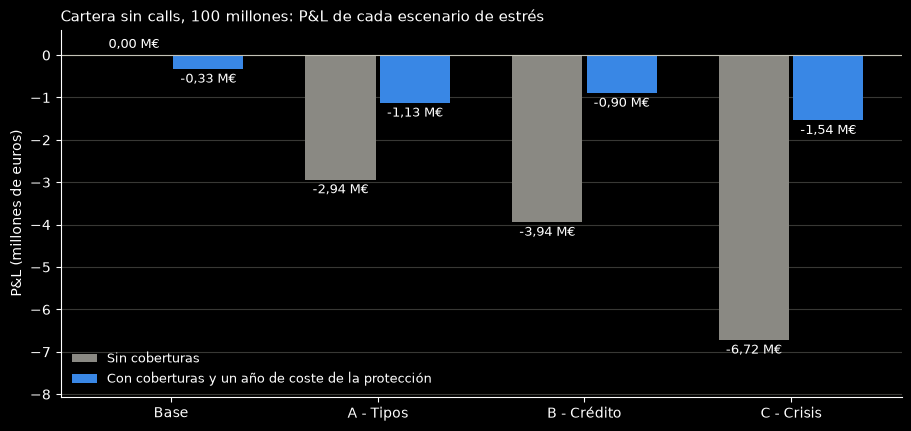

In [130]:
# Stress test con las coberturas de los apartados 7 y 8, escaladas a 100 millones.
# Futuros: recalculamos los contratos sobre el PVBP escalado y redondeamos al final.
escala = capital_estres / capital_cobertura
contratos_estres = cobertura_tipos_elegida.assign(
    Contratos=lambda t: (
        porcentaje_cobertura_tipos * t["PVBPTramo"] * escala / t["Futuro"].map(pvbp_contrato)
    ).round().astype(int)
).set_index(["Escenario", "Futuro"])["Contratos"]
# CDS: la protección elegida en el apartado 8 (la cartera con calls no se cubre).
# Sensibilidad del enunciado: 4.500 euros por pb por cada 10 millones de nominal.
nominal_cds_estres = (cobertura_credito["NominalProteccion"] * escala).to_dict()
sensibilidad_cds = 4_500 / 10_000_000
# Coste de la protección: prima anual = nominal × spread del Main a 01/10/2026.
# Lo imputamos para un año en todos los escenarios, también en el base,
# porque es lo que cuesta mantener la cobertura. La prima queda fijada al contratar.
horizonte_coste_anios = 1.0
coste_proteccion = {
    nombre: nominal * spread_main / 10_000 * horizonte_coste_anios
    for nombre, nominal in nominal_cds_estres.items()
}

filas_coberturas = []
for nombre, tabla_estres in resultados_estres.items():
    for (_, fila), (shock_tipos, shock_ig, _) in zip(
        tabla_estres.iterrows(), escenarios_estres.values()
    ):
        # Futuros vendidos: ganan si suben los tipos. El shock es paralelo en todos los tramos.
        pl_futuros = sum(
            contratos_estres[nombre, futuro] * pvbp_contrato[futuro] * shock_tipos * 10_000
            for futuro in tramos["Futuro"]
        )
        # Protección comprada: gana si sube el spread del Main. Al ser un índice IG,
        # suponemos que se mueve como el shock IG del escenario.
        pl_cds = nominal_cds_estres[nombre] * sensibilidad_cds * shock_ig * 10_000
        pl_total = fila["P&L"] + pl_futuros + pl_cds - coste_proteccion[nombre]
        filas_coberturas.append({
            "Cartera": nombre, "Escenario": fila["Escenario"],
            "PLBonos": fila["P&L"], "PLFuturos": pl_futuros, "PLCDS": pl_cds,
            "CosteProteccion": 0.0 - coste_proteccion[nombre],
            "ValorCartera": capital_estres + pl_total, "P&L": pl_total,
            "P&LPct": 100 * pl_total / capital_estres,
            "P&LSinCoberturaPct": 100 * fila["P&L"] / capital_estres,
        })
estres_coberturas = pd.DataFrame(filas_coberturas)
estres_coberturas.to_csv(salida_apartado_9 / "stress_test_con_coberturas.csv", index=False)

print("Coberturas a 100 millones")
display(pd.DataFrame({
    "Contratos Schatz vendidos": contratos_estres.xs("Schatz", level="Futuro"),
    "Contratos BOBL vendidos": contratos_estres.xs("BOBL", level="Futuro"),
    "Nominal protección iTraxx Main (€)": pd.Series(nominal_cds_estres),
    "Coste anual de la protección (€)": pd.Series(coste_proteccion),
}).round(0))
print("P&L en euros con coberturas, con un año de coste de la protección (positivo = ganancia)")
with pd.option_context("display.float_format", "{:,.2f}".format):
    display(estres_coberturas.set_index(["Cartera", "Escenario"]))

# Gráfico para la cartera sin calls: P&L de cada escenario sin y con coberturas.
datos_grafico = estres_coberturas.loc[
    estres_coberturas["Cartera"].eq("Sin calls")
]
fig, eje = plt.subplots(figsize=(9, 4.2), layout="constrained")
anchura = 0.36
x = range(len(datos_grafico))
for k, (columna, etiqueta, color) in enumerate([
    ("PLBonos", "Sin coberturas", "#8a8983"),
    ("P&L", "Con coberturas y un año de coste de la protección", "#3987e5"),
]):
    barras = eje.bar([i + (k - 0.5) * anchura for i in x], datos_grafico[columna] / 1e6,
                     width=anchura - 0.02, color=color, label=etiqueta)
    eje.bar_label(barras, labels=[
        f"{v / 1e6:,.2f} M€".replace(".", ",") for v in datos_grafico[columna]
    ], padding=3, fontsize=9)
eje.axhline(0, color="#c3c2b7", linewidth=0.8)
eje.set_xticks(list(x), datos_grafico["Escenario"])
eje.set_ylabel("P&L (millones de euros)")
eje.set_ylim(1.2 * datos_grafico["PLBonos"].min() / 1e6, 0.6)
eje.spines[["top", "right"]].set_visible(False)
eje.grid(axis="y", color="#383835", linewidth=0.8)
eje.set_axisbelow(True)
eje.legend(frameon=False, fontsize=9, loc="lower left")
eje.set_title("Cartera sin calls, 100 millones: P&L de cada escenario de estrés", loc="left", fontsize=11)
plt.show()

Revaloramos las posiciones de bonos de cada cartera con una inversión de 100 millones de euros, conservando las cantidades compradas y la fecha de valoración. Utilizamos los flujos descontados al z-spread calibrado del apartado 8. Cada valor actual se multiplica por exp(−(shock de tipos + shock de spread) × plazo). Esta revaloración incorpora la convexidad de los flujos fijos.

Aplicamos los shocks del enunciado: +100 pb en tipos, +150 pb en crédito IG y +50 pb en HY. Tratamos los NR como HY a efectos del shock, una hipótesis de clasificación. En crisis se suman ambos desplazamientos. P&L se calcula respecto a los 100 millones iniciales; el escenario base debe reproducir ese importe dentro de la tolerancia numérica.

Las primeras tablas (y stress_test.csv) describen el riesgo de los bonos sin coberturas. La cartera con calls conserva las fechas de rescate supuestas y la cartera sin calls mantiene los flujos a vencimiento. El ejercicio no cambia las decisiones de rescate, introduce impagos ni modeliza cambios de liquidez; por ello, el escenario de crisis representa únicamente los shocks de tipos y spreads especificados.

#### Con las coberturas de los apartados 7 y 8

Añadimos el P&L de las coberturas elegidas, escaladas a 100 millones: en la cartera sin calls, 432 Schatz y 207 BOBL vendidos (75 % del PVBP de cada tramo) y protección comprada sobre el iTraxx Main por 49.986.840 € de nominal (75 % del CS01). En la cartera con calls solo hay 27 Schatz vendidos, porque en el apartado 8 decidimos no cubrir su crédito. El P&L de los futuros y del CDS es lineal, con las sensibilidades de los apartados 7 y 8. Suponemos que el Main sube lo mismo que el shock IG (150 pb), al ser un índice de grado de inversión. Restamos además un año de coste de la protección, 328.554 € (nominal × spread del Main de 65,73 pb), en todos los escenarios, también en el base: es lo que cuesta mantener la cobertura aunque no haya estrés. La prima queda fijada al contratar, así que no sube con el shock. Los resultados se guardan en stress_test_con_coberturas.csv.

| Cartera sin calls | Sin coberturas | Con coberturas, antes de costes | Con coberturas y un año de coste |
|---|---|---|---|
| Base | 0 € | 0 € | −328.554 € (−0,33 %) |
| A - Tipos | −2.937.068 € (−2,94 %) | −799.713 € (−0,80 %) | −1.128.266 € (−1,13 %) |
| B - Crédito | −3.941.533 € (−3,94 %) | −567.421 € (−0,57 %) | −895.974 € (−0,90 %) |
| C - Crisis | −6.720.591 € (−6,72 %) | −1.209.124 € (−1,21 %) | −1.537.677 € (−1,54 %) |

Las coberturas reducen la pérdida de la crisis de un 6,72 % a un 1,54 % del capital, incluido el coste de la protección. Ese coste equivale a 0,33 puntos de rentabilidad al año y se paga también si no llega el estrés: es el precio del seguro frente a pérdidas de hasta 5,18 millones evitadas en la crisis. Lo que queda es, sobre todo, el 25 % que decidimos no cubrir en cada riesgo. En el escenario B la cobertura compensa algo más de lo esperado porque el CDS se dimensiona sobre todo el CS01, pero el bono sin rating (10 %) solo sufre el shock HY de 50 pb mientras suponemos que el índice sube 150 pb. En la cartera con calls el efecto es pequeño: la pérdida de la crisis pasa de 195.615 € a 141.222 €, porque su duración es muy baja y su crédito no se cubre.

Este resultado es optimista en dos aspectos. Supone que el índice se mueve exactamente como nuestros bonos, sin riesgo de base, y que los tipos suben por igual en todos los plazos, que es el caso más favorable para la cobertura con futuros. Tampoco incluye las comisiones y las garantías de los futuros, cuyo coste es pequeño frente al de la protección, ni el impago de un emisor concreto.
